# Shared setup

In [1]:
%pip install gymnasium numpy torch matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.distributions import Categorical


## Experiment settings

Each environment uses the three algorithms below, with 600 training episodes
per independent run and training seeds 42, 43, and 44. Evaluate for 10 episodes
before training and after every 100 training episodes. Final evaluation uses
10 additional episodes with separate seeds.

The shared configuration also defines the discount factor, hidden-layer size,
device, and learning rates. Environment sections use these settings and specify
their own observation features, action meanings, and episode boundaries.

Networks and input tensors use CPU.


In [3]:
TRAIN_EPISODES = 600
TRAIN_SEEDS = (42, 43, 44)
EVAL_EVERY = 100
EVAL_EPISODES = 10
FINAL_EVAL_EPISODES = 10
GAMMA = 1.0
HIDDEN_SIZE = 32
EXPERIMENT_DEVICE = torch.device("cpu")
print("Training device:", EXPERIMENT_DEVICE)

ALGORITHM_NAMES = (
    "REINFORCE", "REINFORCE with baseline", "One-step Actor-Critic"
)
LEARNING_RATES = {
    "REINFORCE": {"policy": 1e-3, "value": None},
    "REINFORCE with baseline": {"policy": 1e-3, "value": 3e-3},
    "One-step Actor-Critic": {"policy": 3e-4, "value": 1e-3},
}


Training device: cpu


In [4]:
def optimizer_step(loss, optimizer):
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()


def compute_sampled_returns(rewards, gamma):
    returns = [0.0] * len(rewards)
    future_return = 0.0
    for t in reversed(range(len(rewards))):
        future_return = float(rewards[t]) + gamma * future_return
        returns[t] = future_return
    return returns


# Shared methods and experiment workflow

## Networks

Each independent run creates fresh policy parameters and an Adam optimizer.
REINFORCE with baseline and Actor-Critic also create a value network with its own
parameters and Adam optimizer. The policy outputs action logits; Categorical
constructs the corresponding probability distribution. Network input and output
sizes are specified in each environment section.

## REINFORCE and REINFORCE with baseline

Let $t$ index the steps in an episode of length $T$. The policy selects action
$a_t$ from observation $s_t$ with probability $\pi_\theta(a_t\mid s_t)$, where
$\theta$ denotes the policy parameters. The environment then returns reward
$R_{t+1}$. The discount factor is $\gamma$, and the sampled return is

$$G_t=\sum_{k=t}^{T-1}\gamma^{k-t}R_{k+1}.$$

Write $V(s_t,t)$ for the value network's estimate at step $t$, using that
environment's value inputs. CartPole, Taxi, FrozenLake, and CliffWalking include
remaining time in those inputs. Blackjack's estimate depends only on the
observation, so $V(s_t,t)=V(s_t)$ there.

Collect a complete episode, then compute the policy loss function. For REINFORCE:

$$L_{\mathrm{policy}}(\theta)
=-\sum_{t=0}^{T-1}\gamma^t G_t\ln\pi_\theta(a_t\mid s_t).$$

For REINFORCE with baseline:

$$L_{\mathrm{policy}}(\theta)
=-\sum_{t=0}^{T-1}\gamma^t\bigl[G_t-V(s_t,t)\bigr]
\ln\pi_\theta(a_t\mid s_t).$$

Treat the sampled returns and the baseline-weighted differences as constants
when differentiating the policy loss function. The value loss function is

$$L_{\mathrm{value}}=\frac{1}{2T}\sum_{t=0}^{T-1}(V(s_t,t)-G_t)^2,$$

with $G_t$ treated as constant. Adam applies one policy update using the sum of
the episode's policy terms. The baseline version also applies one value update
per episode.

## One-step Actor-Critic

After each action, form the training target:

$$\mathrm{target}=\begin{cases}
R_{t+1}, & \text{if the task terminates},\\
R_{t+1}+\gamma V(s_{t+1},t+1), & \text{otherwise}.
\end{cases}$$

The environment section specifies the task's terminal boundary. The TD error
is $\mathrm{target}-V(s_t,t)$. The per-step loss functions are

$$L_{\mathrm{policy}}(\theta)
=-\gamma^t\bigl[\mathrm{target}-V(s_t,t)\bigr]
\ln\pi_\theta(a_t\mid s_t),$$

$$L_{\mathrm{value}}=\tfrac12\bigl(V(s_t,t)-\mathrm{target}\bigr)^2.$$

Treat the target as constant in the value loss function and the TD error as
constant in the policy loss function. Apply one update to each network after
each action, then sample the next action from the updated policy.


## Evaluation

Keep the policy parameters fixed and sample actions in a separate environment.
Each evaluation episode uses its own environment seed; set the action seed once
for the entire evaluation. For a given training seed, all algorithms use the
same evaluation seed schedule at each checkpoint. Restore the PyTorch
random-number state afterward to preserve the sequence used for training actions.
Final evaluation uses a separate seed schedule.

## Run the experiment

Each training function call runs one algorithm with one training seed. Each
training episode resets the environment with its own seed. The experiment loop
runs three algorithms with three seeds, giving nine independent runs per
environment. Progress output reports completed training episodes and the current
evaluation mean. Evaluation episodes are additional to the training budget.

## Compare the three algorithms

At each checkpoint, average evaluation episode returns within each independent
run, then average the three run means. Plot one line per algorithm: completed
training episodes on the horizontal axis and mean undiscounted episode return
on the vertical axis. The printed final means use the additional final
evaluation episodes, averaged across the three runs.

Algorithms receive equal training-episode budgets within each environment;
their environment-step and parameter-update counts can differ. The small
evaluation sample can produce noticeable variation between checkpoints.


## Method references

- Sutton and Barto, *Reinforcement Learning: An Introduction*, second edition,
  Sections 13.3-13.5.
- [PyTorch Categorical distribution](https://docs.pytorch.org/docs/stable/distributions.html#categorical)


# CartPole: Policy Gradient Methods

In CartPole-v1, action 0 pushes the cart left and action 1 pushes it right.
The four observations are cart position, cart velocity, pole angle, and pole
angular velocity. Each completed step gives a reward of +1.

The task ends at failure or after 500 steps. This 500-step limit is the length
limit of one episode. The Actor-Critic target uses only the current reward at
either task boundary. With the shared discount factor of 1, episode return
equals the number of steps completed.

Environment rules: [Gymnasium CartPole documentation](https://gymnasium.farama.org/environments/classic_control/cart_pole/).


In [5]:
MAX_EPISODE_STEPS = 500


## Networks and observations

The policy network receives the four physical observations and uses
`Linear(4, 32) -> Tanh -> Linear(32, 2)`.

The value network receives those observations plus the remaining-time fraction
`(MAX_EPISODE_STEPS - step_index) / MAX_EPISODE_STEPS`. Its architecture is
`Linear(5, 32) -> Tanh -> Linear(32, 1)`.


In [6]:
def make_policy_network(seed):
    # Network initialization must not consume the training-action random stream.
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(seed)
        network = nn.Sequential(
            nn.Linear(4, HIDDEN_SIZE), nn.Tanh(), nn.Linear(HIDDEN_SIZE, 2)
        )
    return network.to(EXPERIMENT_DEVICE)


def make_value_network(seed):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(seed)
        network = nn.Sequential(
            nn.Linear(5, HIDDEN_SIZE), nn.Tanh(), nn.Linear(HIDDEN_SIZE, 1)
        )
    return network.to(EXPERIMENT_DEVICE)


def observation_to_tensor(observation):
    return torch.as_tensor(observation, dtype=torch.float32, device=EXPERIMENT_DEVICE)


def value_features(observation, step_index):
    remaining_fraction = (MAX_EPISODE_STEPS - step_index) / MAX_EPISODE_STEPS
    return observation_to_tensor(np.append(observation, remaining_fraction))


## REINFORCE and REINFORCE with baseline


In [7]:
def collect_cartpole_episode(policy_network, environment, reset_seed):
    observation, _ = environment.reset(seed=reset_seed)
    observations, actions, rewards = [], [], []
    terminated = truncated = False
    while not (terminated or truncated):
        with torch.no_grad():
            distribution = Categorical(
                logits=policy_network(observation_to_tensor(observation))
            )
            action = int(distribution.sample().item())
        next_observation, reward, terminated, truncated, _ = environment.step(action)
        observations.append(observation.copy())
        actions.append(action)
        rewards.append(float(reward))
        observation = next_observation
    return observations, actions, rewards


def train_reinforce_episode(
    policy_network, policy_optimizer, environment, reset_seed,
    value_network=None, value_optimizer=None,
):
    observations, actions, rewards = collect_cartpole_episode(
        policy_network, environment, reset_seed
    )
    observation_tensor = observation_to_tensor(np.asarray(observations))
    actions = torch.tensor(actions, dtype=torch.long, device=EXPERIMENT_DEVICE)
    returns = torch.tensor(
        compute_sampled_returns(rewards, GAMMA),
        dtype=torch.float32, device=EXPERIMENT_DEVICE,
    )
    discounts = torch.tensor(
        [GAMMA ** t for t in range(len(rewards))],
        dtype=torch.float32, device=EXPERIMENT_DEVICE,
    )
    distribution = Categorical(logits=policy_network(observation_tensor))
    action_log_probabilities = distribution.log_prob(actions)
    policy_weights = returns

    if value_network is not None:
        features = torch.stack([
            value_features(observation, t)
            for t, observation in enumerate(observations)
        ])
        values = value_network(features).squeeze(-1)
        policy_weights = returns - values.detach()
        value_loss = 0.5 * (values - returns).square().mean()

    policy_loss = -(discounts * policy_weights * action_log_probabilities).sum()
    optimizer_step(policy_loss, policy_optimizer)
    if value_network is not None:
        optimizer_step(value_loss, value_optimizer)


## One-step Actor-Critic


In [8]:
def train_actor_critic_episode(
    policy_network, policy_optimizer, value_network, value_optimizer,
    environment, reset_seed,
):
    observation, _ = environment.reset(seed=reset_seed)
    terminated = truncated = False
    step_index = 0
    while not (terminated or truncated):
        distribution = Categorical(
            logits=policy_network(observation_to_tensor(observation))
        )
        action_tensor = distribution.sample()
        action_log_probability = distribution.log_prob(action_tensor)
        value = value_network(value_features(observation, step_index)).squeeze(-1)
        next_observation, reward, terminated, truncated, _ = environment.step(
            int(action_tensor.item())
        )

        with torch.no_grad():
            if terminated or truncated:
                target = torch.tensor(float(reward), device=EXPERIMENT_DEVICE)
            else:
                next_value = value_network(
                    value_features(next_observation, step_index + 1)
                ).squeeze(-1)
                target = float(reward) + GAMMA * next_value
            td_error = target - value.detach()

        policy_loss = -(GAMMA ** step_index) * td_error * action_log_probability
        value_loss = 0.5 * (value - target).square()
        optimizer_step(policy_loss, policy_optimizer)
        optimizer_step(value_loss, value_optimizer)
        observation = next_observation
        step_index += 1


## Evaluation


In [9]:
def evaluate_cartpole(policy_network, environment_seeds, action_seed):
    environment = gym.make("CartPole-v1", max_episode_steps=MAX_EPISODE_STEPS)
    returns = []
    try:
        with torch.random.fork_rng(devices=[]), torch.no_grad():
            torch.manual_seed(action_seed)
            for environment_seed in environment_seeds:
                observation, _ = environment.reset(seed=environment_seed)
                total_reward = 0.0
                terminated = truncated = False
                while not (terminated or truncated):
                    distribution = Categorical(
                        logits=policy_network(observation_to_tensor(observation))
                    )
                    action = int(distribution.sample().item())
                    observation, reward, terminated, truncated, _ = environment.step(action)
                    total_reward += float(reward)
                returns.append(total_reward)
    finally:
        environment.close()
    return float(np.mean(returns))


## Run the experiment


In [10]:
def run_cartpole_training(algorithm, seed):
    torch.manual_seed(seed)
    policy_network = make_policy_network(seed)
    rates = LEARNING_RATES[algorithm]
    policy_optimizer = torch.optim.Adam(
        policy_network.parameters(), lr=rates["policy"]
    )
    value_network = value_optimizer = None
    if algorithm != "REINFORCE":
        value_network = make_value_network(seed + 10000)
        value_optimizer = torch.optim.Adam(
            value_network.parameters(), lr=rates["value"]
        )

    environment = gym.make("CartPole-v1", max_episode_steps=MAX_EPISODE_STEPS)
    evaluation_seeds = [1000000 + seed * 1000 + i for i in range(EVAL_EPISODES)]
    evaluation_episodes, evaluation_means = [], []

    def record_evaluation(episode_number):
        mean_return = evaluate_cartpole(policy_network, evaluation_seeds, 3000000 + seed)
        evaluation_episodes.append(episode_number)
        evaluation_means.append(mean_return)
        print(
            f"{algorithm} | seed={seed} | episode={episode_number}/{TRAIN_EPISODES} | "
            f"eval_mean={mean_return:.1f}", flush=True
        )

    try:
        record_evaluation(0)
        for episode_number in range(1, TRAIN_EPISODES + 1):
            reset_seed = seed * 10000 + episode_number
            if algorithm == "One-step Actor-Critic":
                train_actor_critic_episode(
                    policy_network, policy_optimizer, value_network, value_optimizer,
                    environment, reset_seed,
                )
            else:
                train_reinforce_episode(
                    policy_network, policy_optimizer, environment, reset_seed,
                    value_network, value_optimizer,
                )
            if episode_number % EVAL_EVERY == 0 or episode_number == TRAIN_EPISODES:
                record_evaluation(episode_number)

        final_seeds = [2000000 + seed * 1000 + i for i in range(FINAL_EVAL_EPISODES)]
        final_mean = evaluate_cartpole(policy_network, final_seeds, 4000000 + seed)
    finally:
        environment.close()

    return {
        "algorithm": algorithm, "seed": seed,
        "evaluation_episodes": evaluation_episodes,
        "evaluation_means": evaluation_means,
        "final_mean": final_mean,
    }


cartpole_results = []
for algorithm in ALGORITHM_NAMES:
    for seed in TRAIN_SEEDS:
        result = run_cartpole_training(algorithm, seed)
        cartpole_results.append(result)
        print(f"Completed {algorithm}, seed={seed}: final_mean={result['final_mean']:.1f}")


REINFORCE | seed=42 | episode=0/600 | eval_mean=24.0
REINFORCE | seed=42 | episode=100/600 | eval_mean=31.8
REINFORCE | seed=42 | episode=200/600 | eval_mean=49.8
REINFORCE | seed=42 | episode=300/600 | eval_mean=181.0
REINFORCE | seed=42 | episode=400/600 | eval_mean=167.4
REINFORCE | seed=42 | episode=500/600 | eval_mean=156.2
REINFORCE | seed=42 | episode=600/600 | eval_mean=362.9
Completed REINFORCE, seed=42: final_mean=384.0
REINFORCE | seed=43 | episode=0/600 | eval_mean=18.6
REINFORCE | seed=43 | episode=100/600 | eval_mean=44.6
REINFORCE | seed=43 | episode=200/600 | eval_mean=60.3
REINFORCE | seed=43 | episode=300/600 | eval_mean=95.5
REINFORCE | seed=43 | episode=400/600 | eval_mean=323.8
REINFORCE | seed=43 | episode=500/600 | eval_mean=481.4
REINFORCE | seed=43 | episode=600/600 | eval_mean=313.5
Completed REINFORCE, seed=43: final_mean=274.2
REINFORCE | seed=44 | episode=0/600 | eval_mean=20.0
REINFORCE | seed=44 | episode=100/600 | eval_mean=42.8
REINFORCE | seed=44 | epi

## Compare the three algorithms


REINFORCE: final mean return across 3 runs = 335.83
REINFORCE with baseline: final mean return across 3 runs = 468.23
One-step Actor-Critic: final mean return across 3 runs = 172.70


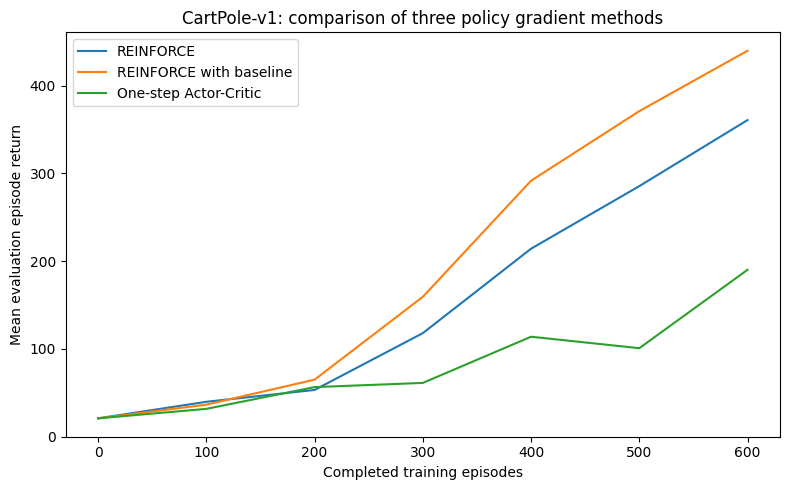

In [11]:
plt.figure(figsize=(8, 5))
for algorithm in ALGORITHM_NAMES:
    runs = [result for result in cartpole_results if result["algorithm"] == algorithm]
    mean_returns = np.mean([run["evaluation_means"] for run in runs], axis=0)
    plt.plot(runs[0]["evaluation_episodes"], mean_returns, label=algorithm)
    final_mean = np.mean([run["final_mean"] for run in runs])
    print(f"{algorithm}: final mean return across {len(runs)} runs = {final_mean:.2f}")

plt.xlabel("Completed training episodes")
plt.ylabel("Mean evaluation episode return")
plt.title("CartPole-v1: comparison of three policy gradient methods")
plt.legend()
plt.tight_layout()
plt.show()


# Blackjack: Policy Gradient Methods

Blackjack-v1 uses `natural=False, sab=False`. Action 0 means stick; action 1
means hit. The observation contains the player's total, the dealer's visible
card, and whether the player has an ace counted as 11. Cards are drawn with
replacement; the environment plays the dealer's hand after the player sticks.

A round ends when the player sticks or busts. Winning gives +1, losing gives
-1, and drawing gives 0; a nonterminal hit gives 0. With the shared discount
factor of 1, every step's sampled return in a round equals that round's final
outcome. Mean return equals the fraction of wins minus the fraction of losses.
A higher value is better.

Environment rules: [Gymnasium Blackjack documentation](https://gymnasium.farama.org/environments/toy_text/blackjack/).


In [12]:
BLACKJACK_TRAIN_EPISODES = TRAIN_EPISODES
BLACKJACK_TRAIN_SEEDS = TRAIN_SEEDS
BLACKJACK_EVAL_EVERY = EVAL_EVERY
BLACKJACK_EVAL_EPISODES = EVAL_EPISODES
BLACKJACK_FINAL_EVAL_EPISODES = FINAL_EVAL_EPISODES
BLACKJACK_GAMMA = GAMMA
BLACKJACK_HIDDEN_SIZE = HIDDEN_SIZE
BLACKJACK_DEVICE = EXPERIMENT_DEVICE
BLACKJACK_ALGORITHM_NAMES = ALGORITHM_NAMES
BLACKJACK_LEARNING_RATES = LEARNING_RATES


## Networks and observations

Both networks use three input features: player total divided by 32, dealer card
value divided by 10, and the usable-ace indicator (0 or 1). Scaling the two card
values keeps their magnitudes comparable to the indicator.

The policy architecture is `Linear(3, 32) -> Tanh -> Linear(32, 2)`.
The value architecture is `Linear(3, 32) -> Tanh -> Linear(32, 1)`.


In [13]:
def make_blackjack_environment():
    return gym.make("Blackjack-v1", natural=False, sab=False)


def blackjack_features(observation):
    player_total, dealer_card, usable_ace = observation
    return torch.tensor(
        [player_total / 32.0, dealer_card / 10.0, float(usable_ace)],
        dtype=torch.float32, device=BLACKJACK_DEVICE,
    )


def make_blackjack_policy_network(seed):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(seed)
        network = nn.Sequential(
            nn.Linear(3, BLACKJACK_HIDDEN_SIZE), nn.Tanh(),
            nn.Linear(BLACKJACK_HIDDEN_SIZE, 2),
        )
    return network.to(BLACKJACK_DEVICE)


def make_blackjack_value_network(seed):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(seed)
        network = nn.Sequential(
            nn.Linear(3, BLACKJACK_HIDDEN_SIZE), nn.Tanh(),
            nn.Linear(BLACKJACK_HIDDEN_SIZE, 1),
        )
    return network.to(BLACKJACK_DEVICE)


## REINFORCE and REINFORCE with baseline


In [14]:
def collect_blackjack_episode(policy_network, environment, reset_seed):
    observation, _ = environment.reset(seed=reset_seed)
    observations, actions, rewards = [], [], []
    terminated = truncated = False
    while not (terminated or truncated):
        with torch.no_grad():
            distribution = Categorical(logits=policy_network(blackjack_features(observation)))
            action = int(distribution.sample().item())
        next_observation, reward, terminated, truncated, _ = environment.step(action)
        observations.append(observation)
        actions.append(action)
        rewards.append(float(reward))
        observation = next_observation
    return observations, actions, rewards


def train_blackjack_reinforce_episode(
    policy_network, policy_optimizer, environment, reset_seed,
    value_network=None, value_optimizer=None,
):
    observations, actions, rewards = collect_blackjack_episode(
        policy_network, environment, reset_seed
    )
    features = torch.stack([blackjack_features(observation) for observation in observations])
    actions = torch.tensor(actions, dtype=torch.long, device=BLACKJACK_DEVICE)
    returns = torch.tensor(
        compute_sampled_returns(rewards, BLACKJACK_GAMMA),
        dtype=torch.float32, device=BLACKJACK_DEVICE,
    )
    discounts = torch.tensor(
        [BLACKJACK_GAMMA ** t for t in range(len(rewards))],
        dtype=torch.float32, device=BLACKJACK_DEVICE,
    )
    distribution = Categorical(logits=policy_network(features))
    action_log_probabilities = distribution.log_prob(actions)
    policy_weights = returns

    if value_network is not None:
        values = value_network(features).squeeze(-1)
        policy_weights = returns - values.detach()
        value_loss = 0.5 * (values - returns).square().mean()

    policy_loss = -(discounts * policy_weights * action_log_probabilities).sum()
    optimizer_step(policy_loss, policy_optimizer)
    if value_network is not None:
        optimizer_step(value_loss, value_optimizer)


## One-step Actor-Critic


In [15]:
def train_blackjack_actor_critic_episode(
    policy_network, policy_optimizer, value_network, value_optimizer,
    environment, reset_seed,
):
    observation, _ = environment.reset(seed=reset_seed)
    terminated = truncated = False
    step_index = 0
    while not (terminated or truncated):
        features = blackjack_features(observation)
        distribution = Categorical(logits=policy_network(features))
        action_tensor = distribution.sample()
        action_log_probability = distribution.log_prob(action_tensor)
        value = value_network(features).squeeze(-1)
        next_observation, reward, terminated, truncated, _ = environment.step(
            int(action_tensor.item())
        )

        with torch.no_grad():
            if terminated:
                target = torch.tensor(float(reward), device=BLACKJACK_DEVICE)
            else:
                next_value = value_network(blackjack_features(next_observation)).squeeze(-1)
                target = float(reward) + BLACKJACK_GAMMA * next_value
            td_error = target - value.detach()

        policy_loss = -(BLACKJACK_GAMMA ** step_index) * td_error * action_log_probability
        value_loss = 0.5 * (value - target).square()
        optimizer_step(policy_loss, policy_optimizer)
        optimizer_step(value_loss, value_optimizer)
        observation = next_observation
        step_index += 1


## Evaluation


In [16]:
def evaluate_blackjack(policy_network, environment_seeds, action_seed):
    environment = make_blackjack_environment()
    returns = []
    try:
        with torch.random.fork_rng(devices=[]), torch.no_grad():
            torch.manual_seed(action_seed)
            for environment_seed in environment_seeds:
                observation, _ = environment.reset(seed=environment_seed)
                total_reward = 0.0
                terminated = truncated = False
                while not (terminated or truncated):
                    distribution = Categorical(
                        logits=policy_network(blackjack_features(observation))
                    )
                    action = int(distribution.sample().item())
                    observation, reward, terminated, truncated, _ = environment.step(action)
                    total_reward += float(reward)
                returns.append(total_reward)
    finally:
        environment.close()
    return float(np.mean(returns))


## Run the experiment


In [17]:
def run_blackjack_training(algorithm, seed):
    torch.manual_seed(seed)
    policy_network = make_blackjack_policy_network(seed)
    rates = BLACKJACK_LEARNING_RATES[algorithm]
    policy_optimizer = torch.optim.Adam(policy_network.parameters(), lr=rates["policy"])
    value_network = value_optimizer = None
    if algorithm != "REINFORCE":
        value_network = make_blackjack_value_network(seed + 10000)
        value_optimizer = torch.optim.Adam(value_network.parameters(), lr=rates["value"])

    environment = make_blackjack_environment()
    evaluation_seeds = [1000000 + seed * 1000 + i for i in range(BLACKJACK_EVAL_EPISODES)]
    evaluation_episodes, evaluation_means = [], []

    def record_evaluation(episode_number):
        mean_return = evaluate_blackjack(policy_network, evaluation_seeds, 3000000 + seed)
        evaluation_episodes.append(episode_number)
        evaluation_means.append(mean_return)
        print(
            f"Blackjack | {algorithm} | seed={seed} | "
            f"episode={episode_number}/{BLACKJACK_TRAIN_EPISODES} | "
            f"eval_mean={mean_return:.2f}", flush=True
        )

    try:
        record_evaluation(0)
        for episode_number in range(1, BLACKJACK_TRAIN_EPISODES + 1):
            reset_seed = seed * 10000 + episode_number
            if algorithm == "One-step Actor-Critic":
                train_blackjack_actor_critic_episode(
                    policy_network, policy_optimizer, value_network, value_optimizer,
                    environment, reset_seed,
                )
            else:
                train_blackjack_reinforce_episode(
                    policy_network, policy_optimizer, environment, reset_seed,
                    value_network, value_optimizer,
                )
            if (episode_number % BLACKJACK_EVAL_EVERY == 0
                    or episode_number == BLACKJACK_TRAIN_EPISODES):
                record_evaluation(episode_number)

        final_seeds = [
            2000000 + seed * 1000 + i for i in range(BLACKJACK_FINAL_EVAL_EPISODES)
        ]
        final_mean = evaluate_blackjack(policy_network, final_seeds, 4000000 + seed)
    finally:
        environment.close()

    return {
        "algorithm": algorithm, "seed": seed,
        "evaluation_episodes": evaluation_episodes,
        "evaluation_means": evaluation_means, "final_mean": final_mean,
    }


blackjack_results = []
for algorithm in BLACKJACK_ALGORITHM_NAMES:
    for seed in BLACKJACK_TRAIN_SEEDS:
        result = run_blackjack_training(algorithm, seed)
        blackjack_results.append(result)
        print(f"Completed Blackjack | {algorithm}, seed={seed}: final_mean={result['final_mean']:.2f}")


Blackjack | REINFORCE | seed=42 | episode=0/600 | eval_mean=-0.20
Blackjack | REINFORCE | seed=42 | episode=100/600 | eval_mean=-0.30
Blackjack | REINFORCE | seed=42 | episode=200/600 | eval_mean=-0.10
Blackjack | REINFORCE | seed=42 | episode=300/600 | eval_mean=-0.10
Blackjack | REINFORCE | seed=42 | episode=400/600 | eval_mean=-0.10
Blackjack | REINFORCE | seed=42 | episode=500/600 | eval_mean=-0.10
Blackjack | REINFORCE | seed=42 | episode=600/600 | eval_mean=-0.10
Completed Blackjack | REINFORCE, seed=42: final_mean=-0.80
Blackjack | REINFORCE | seed=43 | episode=0/600 | eval_mean=-0.80
Blackjack | REINFORCE | seed=43 | episode=100/600 | eval_mean=0.00
Blackjack | REINFORCE | seed=43 | episode=200/600 | eval_mean=-0.20
Blackjack | REINFORCE | seed=43 | episode=300/600 | eval_mean=0.00
Blackjack | REINFORCE | seed=43 | episode=400/600 | eval_mean=0.00
Blackjack | REINFORCE | seed=43 | episode=500/600 | eval_mean=-0.20
Blackjack | REINFORCE | seed=43 | episode=600/600 | eval_mean=0.

## Compare the three algorithms


Blackjack | REINFORCE: final mean return across 3 runs = -0.53
Blackjack | REINFORCE with baseline: final mean return across 3 runs = -0.53
Blackjack | One-step Actor-Critic: final mean return across 3 runs = -0.53


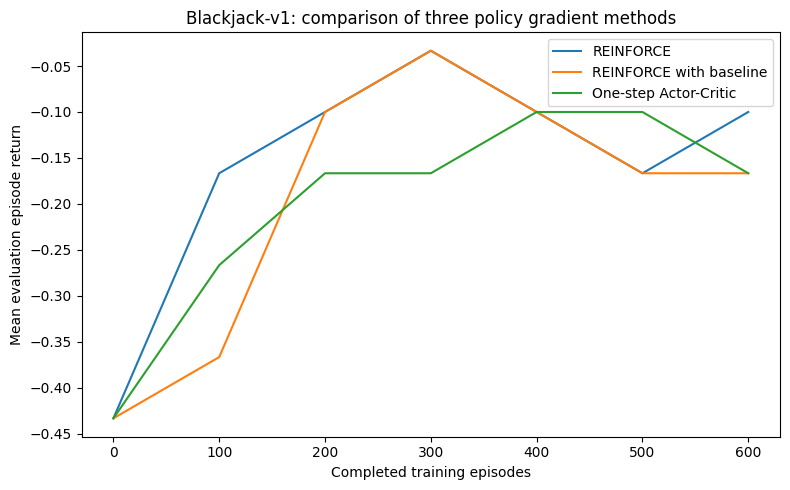

In [18]:
plt.figure(figsize=(8, 5))
for algorithm in BLACKJACK_ALGORITHM_NAMES:
    runs = [result for result in blackjack_results if result["algorithm"] == algorithm]
    mean_returns = np.mean([run["evaluation_means"] for run in runs], axis=0)
    plt.plot(runs[0]["evaluation_episodes"], mean_returns, label=algorithm)
    final_mean = np.mean([run["final_mean"] for run in runs])
    print(f"Blackjack | {algorithm}: final mean return across {len(runs)} runs = {final_mean:.2f}")

plt.xlabel("Completed training episodes")
plt.ylabel("Mean evaluation episode return")
plt.title("Blackjack-v1: comparison of three policy gradient methods")
plt.legend()
plt.tight_layout()
plt.show()


# Taxi: Policy Gradient Methods

The observation is an integer identifying one of 500 combinations of taxi
position, passenger location, and destination. Actions are 0: south, 1: north,
2: east, 3: west, 4: pickup, and 5: drop-off. The policy samples from all six
actions, including actions that can be invalid in the current state.

The reward is -1 for an ordinary step, -10 for an illegal pickup or drop-off,
and +20 for delivery to the correct destination. Successful delivery ends the
episode. Rain and destination changes are disabled.

The experiment uses the standard 200-step limit as a finite task horizon.
Both training and evaluation stop at delivery or at this limit. The value
network receives remaining time; Actor-Critic uses only the final reward at
either boundary. Higher mean episode return is better.

Environment rules: [Gymnasium Taxi documentation](https://gymnasium.farama.org/environments/toy_text/taxi/).


In [19]:
TAXI_TRAIN_EPISODES = TRAIN_EPISODES
TAXI_TRAIN_SEEDS = TRAIN_SEEDS
TAXI_EVAL_EVERY = EVAL_EVERY
TAXI_EVAL_EPISODES = EVAL_EPISODES
TAXI_FINAL_EVAL_EPISODES = FINAL_EVAL_EPISODES
TAXI_GAMMA = GAMMA
TAXI_HIDDEN_SIZE = HIDDEN_SIZE
TAXI_DEVICE = EXPERIMENT_DEVICE
TAXI_ALGORITHM_NAMES = ALGORITHM_NAMES
TAXI_LEARNING_RATES = LEARNING_RATES

TAXI_STATE_COUNT = 500
TAXI_ACTION_COUNT = 6
TAXI_MAX_EPISODE_STEPS = 200


## Networks and observations

The policy input is a one-hot vector of length 500: the observed
state's entry is 1 and every other entry is 0. The state ID is a category,
so its numerical magnitude is not used as an input feature.

The value input appends the fraction of steps remaining to the same state
vector, giving 501 features. At step t, that fraction is
`(MAX_EPISODE_STEPS - t) / MAX_EPISODE_STEPS`, using this environment's limit.

The policy architecture is `Linear(500, 32) -> Tanh -> Linear(32, 6)`.
The value architecture is `Linear(501, 32) -> Tanh -> Linear(32, 1)`.


In [20]:
def make_taxi_environment():
    return gym.make(
        "Taxi-v4", max_episode_steps=TAXI_MAX_EPISODE_STEPS,
        is_rainy=False, fickle_passenger=False,
    )


def taxi_features(observation):
    features = torch.zeros(TAXI_STATE_COUNT, dtype=torch.float32, device=TAXI_DEVICE)
    features[int(observation)] = 1.0
    return features


def taxi_value_features(observation, step_index):
    remaining_time = torch.tensor(
        [(TAXI_MAX_EPISODE_STEPS - step_index) / TAXI_MAX_EPISODE_STEPS],
        dtype=torch.float32, device=TAXI_DEVICE,
    )
    return torch.cat((taxi_features(observation), remaining_time))


def make_taxi_policy_network(seed):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(seed)
        network = nn.Sequential(
            nn.Linear(TAXI_STATE_COUNT, TAXI_HIDDEN_SIZE), nn.Tanh(),
            nn.Linear(TAXI_HIDDEN_SIZE, TAXI_ACTION_COUNT),
        )
    return network.to(TAXI_DEVICE)


def make_taxi_value_network(seed):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(seed)
        network = nn.Sequential(
            nn.Linear(TAXI_STATE_COUNT + 1, TAXI_HIDDEN_SIZE), nn.Tanh(),
            nn.Linear(TAXI_HIDDEN_SIZE, 1),
        )
    return network.to(TAXI_DEVICE)


## REINFORCE and REINFORCE with baseline


In [21]:
def collect_taxi_episode(policy_network, environment, reset_seed):
    observation, _ = environment.reset(seed=reset_seed)
    observations, actions, rewards = [], [], []
    terminated = truncated = False
    while not (terminated or truncated):
        with torch.no_grad():
            distribution = Categorical(logits=policy_network(taxi_features(observation)))
            action = int(distribution.sample().item())
        next_observation, reward, terminated, truncated, _ = environment.step(action)
        observations.append(observation)
        actions.append(action)
        rewards.append(float(reward))
        observation = next_observation
    return observations, actions, rewards


def train_taxi_reinforce_episode(
    policy_network, policy_optimizer, environment, reset_seed,
    value_network=None, value_optimizer=None,
):
    observations, actions, rewards = collect_taxi_episode(
        policy_network, environment, reset_seed
    )
    features = torch.stack([taxi_features(observation) for observation in observations])
    actions = torch.tensor(actions, dtype=torch.long, device=TAXI_DEVICE)
    returns = torch.tensor(
        compute_sampled_returns(rewards, TAXI_GAMMA),
        dtype=torch.float32, device=TAXI_DEVICE,
    )
    discounts = torch.tensor(
        [TAXI_GAMMA ** t for t in range(len(rewards))],
        dtype=torch.float32, device=TAXI_DEVICE,
    )
    distribution = Categorical(logits=policy_network(features))
    action_log_probabilities = distribution.log_prob(actions)
    policy_weights = returns

    if value_network is not None:
        value_inputs = torch.stack([
            taxi_value_features(observation, t)
            for t, observation in enumerate(observations)
        ])
        values = value_network(value_inputs).squeeze(-1)
        policy_weights = returns - values.detach()
        value_loss = 0.5 * (values - returns).square().mean()

    policy_loss = -(discounts * policy_weights * action_log_probabilities).sum()
    optimizer_step(policy_loss, policy_optimizer)
    if value_network is not None:
        optimizer_step(value_loss, value_optimizer)


## One-step Actor-Critic


In [22]:
def train_taxi_actor_critic_episode(
    policy_network, policy_optimizer, value_network, value_optimizer,
    environment, reset_seed,
):
    observation, _ = environment.reset(seed=reset_seed)
    terminated = truncated = False
    step_index = 0
    while not (terminated or truncated):
        features = taxi_features(observation)
        distribution = Categorical(logits=policy_network(features))
        action_tensor = distribution.sample()
        action_log_probability = distribution.log_prob(action_tensor)
        value = value_network(taxi_value_features(observation, step_index)).squeeze(-1)
        next_observation, reward, terminated, truncated, _ = environment.step(
            int(action_tensor.item())
        )

        with torch.no_grad():
            if terminated or truncated:
                target = torch.tensor(float(reward), device=TAXI_DEVICE)
            else:
                next_value = value_network(
                    taxi_value_features(next_observation, step_index + 1)
                ).squeeze(-1)
                target = float(reward) + TAXI_GAMMA * next_value
            td_error = target - value.detach()

        policy_loss = -(TAXI_GAMMA ** step_index) * td_error * action_log_probability
        value_loss = 0.5 * (value - target).square()
        optimizer_step(policy_loss, policy_optimizer)
        optimizer_step(value_loss, value_optimizer)
        observation = next_observation
        step_index += 1


## Evaluation


In [23]:
def evaluate_taxi(policy_network, environment_seeds, action_seed):
    environment = make_taxi_environment()
    returns = []
    try:
        with torch.random.fork_rng(devices=[]), torch.no_grad():
            torch.manual_seed(action_seed)
            for environment_seed in environment_seeds:
                observation, _ = environment.reset(seed=environment_seed)
                total_reward = 0.0
                terminated = truncated = False
                while not (terminated or truncated):
                    distribution = Categorical(
                        logits=policy_network(taxi_features(observation))
                    )
                    action = int(distribution.sample().item())
                    observation, reward, terminated, truncated, _ = environment.step(action)
                    total_reward += float(reward)
                returns.append(total_reward)
    finally:
        environment.close()
    return float(np.mean(returns))


## Run the experiment


In [24]:
def run_taxi_training(algorithm, seed):
    torch.manual_seed(seed)
    policy_network = make_taxi_policy_network(seed)
    rates = TAXI_LEARNING_RATES[algorithm]
    policy_optimizer = torch.optim.Adam(policy_network.parameters(), lr=rates["policy"])
    value_network = value_optimizer = None
    if algorithm != "REINFORCE":
        value_network = make_taxi_value_network(seed + 10000)
        value_optimizer = torch.optim.Adam(value_network.parameters(), lr=rates["value"])

    environment = make_taxi_environment()
    evaluation_seeds = [1000000 + seed * 1000 + i for i in range(TAXI_EVAL_EPISODES)]
    evaluation_episodes, evaluation_means = [], []

    def record_evaluation(episode_number):
        mean_return = evaluate_taxi(policy_network, evaluation_seeds, 3000000 + seed)
        evaluation_episodes.append(episode_number)
        evaluation_means.append(mean_return)
        print(
            f"Taxi | {algorithm} | seed={seed} | "
            f"episode={episode_number}/{TAXI_TRAIN_EPISODES} | "
            f"eval_mean={mean_return:.2f}", flush=True
        )

    try:
        record_evaluation(0)
        for episode_number in range(1, TAXI_TRAIN_EPISODES + 1):
            reset_seed = seed * 10000 + episode_number
            if algorithm == "One-step Actor-Critic":
                train_taxi_actor_critic_episode(
                    policy_network, policy_optimizer, value_network, value_optimizer,
                    environment, reset_seed,
                )
            else:
                train_taxi_reinforce_episode(
                    policy_network, policy_optimizer, environment, reset_seed,
                    value_network, value_optimizer,
                )
            if (episode_number % TAXI_EVAL_EVERY == 0
                    or episode_number == TAXI_TRAIN_EPISODES):
                record_evaluation(episode_number)

        final_seeds = [
            2000000 + seed * 1000 + i for i in range(TAXI_FINAL_EVAL_EPISODES)
        ]
        final_mean = evaluate_taxi(policy_network, final_seeds, 4000000 + seed)
    finally:
        environment.close()

    return {
        "algorithm": algorithm, "seed": seed,
        "evaluation_episodes": evaluation_episodes,
        "evaluation_means": evaluation_means, "final_mean": final_mean,
    }


taxi_results = []
for algorithm in TAXI_ALGORITHM_NAMES:
    for seed in TAXI_TRAIN_SEEDS:
        result = run_taxi_training(algorithm, seed)
        taxi_results.append(result)
        print(f"Completed Taxi | {algorithm}, seed={seed}: final_mean={result['final_mean']:.2f}")


Taxi | REINFORCE | seed=42 | episode=0/600 | eval_mean=-793.10
Taxi | REINFORCE | seed=42 | episode=100/600 | eval_mean=-775.10
Taxi | REINFORCE | seed=42 | episode=200/600 | eval_mean=-774.20
Taxi | REINFORCE | seed=42 | episode=300/600 | eval_mean=-751.70
Taxi | REINFORCE | seed=42 | episode=400/600 | eval_mean=-720.20
Taxi | REINFORCE | seed=42 | episode=500/600 | eval_mean=-720.20
Taxi | REINFORCE | seed=42 | episode=600/600 | eval_mean=-674.10
Completed Taxi | REINFORCE, seed=42: final_mean=-651.60
Taxi | REINFORCE | seed=43 | episode=0/600 | eval_mean=-850.70
Taxi | REINFORCE | seed=43 | episode=100/600 | eval_mean=-837.20
Taxi | REINFORCE | seed=43 | episode=200/600 | eval_mean=-812.90
Taxi | REINFORCE | seed=43 | episode=300/600 | eval_mean=-793.10
Taxi | REINFORCE | seed=43 | episode=400/600 | eval_mean=-798.50
Taxi | REINFORCE | seed=43 | episode=500/600 | eval_mean=-765.20
Taxi | REINFORCE | seed=43 | episode=600/600 | eval_mean=-763.40
Completed Taxi | REINFORCE, seed=43: f

## Compare the three algorithms


Taxi | REINFORCE: final mean return across 3 runs = -674.57
Taxi | REINFORCE with baseline: final mean return across 3 runs = -678.40
Taxi | One-step Actor-Critic: final mean return across 3 runs = -200.90


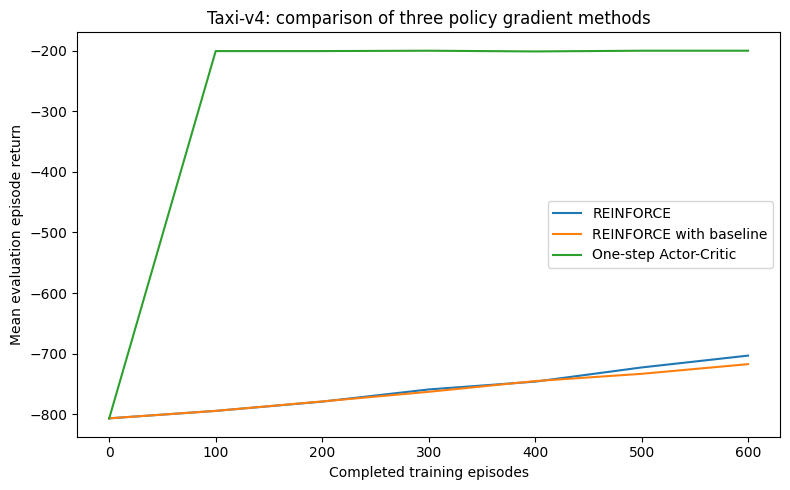

In [25]:
plt.figure(figsize=(8, 5))
for algorithm in TAXI_ALGORITHM_NAMES:
    runs = [result for result in taxi_results if result["algorithm"] == algorithm]
    mean_returns = np.mean([run["evaluation_means"] for run in runs], axis=0)
    plt.plot(runs[0]["evaluation_episodes"], mean_returns, label=algorithm)
    final_mean = np.mean([run["final_mean"] for run in runs])
    print(f"Taxi | {algorithm}: final mean return across {len(runs)} runs = {final_mean:.2f}")

plt.xlabel("Completed training episodes")
plt.ylabel("Mean evaluation episode return")
plt.title("Taxi-v4: comparison of three policy gradient methods")
plt.legend()
plt.tight_layout()
plt.show()


# FrozenLake: Policy Gradient Methods

The fixed 4x4 map uses 16 position IDs. Actions are 0: left, 1: down,
2: right, and 3: up. With `is_slippery=True`, movement follows the selected
direction or either perpendicular direction, each with probability 1/3.

Reaching the goal gives +1; other transitions give 0. Entering a hole or
reaching the goal ends the episode. Mean undiscounted episode return is the
fraction of evaluation episodes that reach the goal.

The experiment uses the standard 100-step limit as a finite task horizon.
The value network receives remaining time; Actor-Critic uses only the final
reward when a hole, the goal, or the time limit ends the episode.

Environment rules: [Gymnasium FrozenLake documentation](https://gymnasium.farama.org/environments/toy_text/frozen_lake/).


In [26]:
FROZENLAKE_TRAIN_EPISODES = TRAIN_EPISODES
FROZENLAKE_TRAIN_SEEDS = TRAIN_SEEDS
FROZENLAKE_EVAL_EVERY = EVAL_EVERY
FROZENLAKE_EVAL_EPISODES = EVAL_EPISODES
FROZENLAKE_FINAL_EVAL_EPISODES = FINAL_EVAL_EPISODES
FROZENLAKE_GAMMA = GAMMA
FROZENLAKE_HIDDEN_SIZE = HIDDEN_SIZE
FROZENLAKE_DEVICE = EXPERIMENT_DEVICE
FROZENLAKE_ALGORITHM_NAMES = ALGORITHM_NAMES
FROZENLAKE_LEARNING_RATES = LEARNING_RATES

FROZENLAKE_STATE_COUNT = 16
FROZENLAKE_ACTION_COUNT = 4
FROZENLAKE_MAX_EPISODE_STEPS = 100


## Networks and observations

The policy input is a one-hot vector of length 16: the observed
state's entry is 1 and every other entry is 0. The state ID is a category,
so its numerical magnitude is not used as an input feature.

The value input appends the fraction of steps remaining to the same state
vector, giving 17 features. At step t, that fraction is
`(MAX_EPISODE_STEPS - t) / MAX_EPISODE_STEPS`, using this environment's limit.

The policy architecture is `Linear(16, 32) -> Tanh -> Linear(32, 4)`.
The value architecture is `Linear(17, 32) -> Tanh -> Linear(32, 1)`.


In [27]:
def make_frozenlake_environment():
    return gym.make(
        "FrozenLake-v1", max_episode_steps=FROZENLAKE_MAX_EPISODE_STEPS,
        map_name="4x4", is_slippery=True,
    )


def frozenlake_features(observation):
    features = torch.zeros(FROZENLAKE_STATE_COUNT, dtype=torch.float32, device=FROZENLAKE_DEVICE)
    features[int(observation)] = 1.0
    return features


def frozenlake_value_features(observation, step_index):
    remaining_time = torch.tensor(
        [(FROZENLAKE_MAX_EPISODE_STEPS - step_index) / FROZENLAKE_MAX_EPISODE_STEPS],
        dtype=torch.float32, device=FROZENLAKE_DEVICE,
    )
    return torch.cat((frozenlake_features(observation), remaining_time))


def make_frozenlake_policy_network(seed):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(seed)
        network = nn.Sequential(
            nn.Linear(FROZENLAKE_STATE_COUNT, FROZENLAKE_HIDDEN_SIZE), nn.Tanh(),
            nn.Linear(FROZENLAKE_HIDDEN_SIZE, FROZENLAKE_ACTION_COUNT),
        )
    return network.to(FROZENLAKE_DEVICE)


def make_frozenlake_value_network(seed):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(seed)
        network = nn.Sequential(
            nn.Linear(FROZENLAKE_STATE_COUNT + 1, FROZENLAKE_HIDDEN_SIZE), nn.Tanh(),
            nn.Linear(FROZENLAKE_HIDDEN_SIZE, 1),
        )
    return network.to(FROZENLAKE_DEVICE)


## REINFORCE and REINFORCE with baseline


In [28]:
def collect_frozenlake_episode(policy_network, environment, reset_seed):
    observation, _ = environment.reset(seed=reset_seed)
    observations, actions, rewards = [], [], []
    terminated = truncated = False
    while not (terminated or truncated):
        with torch.no_grad():
            distribution = Categorical(logits=policy_network(frozenlake_features(observation)))
            action = int(distribution.sample().item())
        next_observation, reward, terminated, truncated, _ = environment.step(action)
        observations.append(observation)
        actions.append(action)
        rewards.append(float(reward))
        observation = next_observation
    return observations, actions, rewards


def train_frozenlake_reinforce_episode(
    policy_network, policy_optimizer, environment, reset_seed,
    value_network=None, value_optimizer=None,
):
    observations, actions, rewards = collect_frozenlake_episode(
        policy_network, environment, reset_seed
    )
    features = torch.stack([frozenlake_features(observation) for observation in observations])
    actions = torch.tensor(actions, dtype=torch.long, device=FROZENLAKE_DEVICE)
    returns = torch.tensor(
        compute_sampled_returns(rewards, FROZENLAKE_GAMMA),
        dtype=torch.float32, device=FROZENLAKE_DEVICE,
    )
    discounts = torch.tensor(
        [FROZENLAKE_GAMMA ** t for t in range(len(rewards))],
        dtype=torch.float32, device=FROZENLAKE_DEVICE,
    )
    distribution = Categorical(logits=policy_network(features))
    action_log_probabilities = distribution.log_prob(actions)
    policy_weights = returns

    if value_network is not None:
        value_inputs = torch.stack([
            frozenlake_value_features(observation, t)
            for t, observation in enumerate(observations)
        ])
        values = value_network(value_inputs).squeeze(-1)
        policy_weights = returns - values.detach()
        value_loss = 0.5 * (values - returns).square().mean()

    policy_loss = -(discounts * policy_weights * action_log_probabilities).sum()
    optimizer_step(policy_loss, policy_optimizer)
    if value_network is not None:
        optimizer_step(value_loss, value_optimizer)


## One-step Actor-Critic


In [29]:
def train_frozenlake_actor_critic_episode(
    policy_network, policy_optimizer, value_network, value_optimizer,
    environment, reset_seed,
):
    observation, _ = environment.reset(seed=reset_seed)
    terminated = truncated = False
    step_index = 0
    while not (terminated or truncated):
        features = frozenlake_features(observation)
        distribution = Categorical(logits=policy_network(features))
        action_tensor = distribution.sample()
        action_log_probability = distribution.log_prob(action_tensor)
        value = value_network(frozenlake_value_features(observation, step_index)).squeeze(-1)
        next_observation, reward, terminated, truncated, _ = environment.step(
            int(action_tensor.item())
        )

        with torch.no_grad():
            if terminated or truncated:
                target = torch.tensor(float(reward), device=FROZENLAKE_DEVICE)
            else:
                next_value = value_network(
                    frozenlake_value_features(next_observation, step_index + 1)
                ).squeeze(-1)
                target = float(reward) + FROZENLAKE_GAMMA * next_value
            td_error = target - value.detach()

        policy_loss = -(FROZENLAKE_GAMMA ** step_index) * td_error * action_log_probability
        value_loss = 0.5 * (value - target).square()
        optimizer_step(policy_loss, policy_optimizer)
        optimizer_step(value_loss, value_optimizer)
        observation = next_observation
        step_index += 1


## Evaluation


In [30]:
def evaluate_frozenlake(policy_network, environment_seeds, action_seed):
    environment = make_frozenlake_environment()
    returns = []
    try:
        with torch.random.fork_rng(devices=[]), torch.no_grad():
            torch.manual_seed(action_seed)
            for environment_seed in environment_seeds:
                observation, _ = environment.reset(seed=environment_seed)
                total_reward = 0.0
                terminated = truncated = False
                while not (terminated or truncated):
                    distribution = Categorical(
                        logits=policy_network(frozenlake_features(observation))
                    )
                    action = int(distribution.sample().item())
                    observation, reward, terminated, truncated, _ = environment.step(action)
                    total_reward += float(reward)
                returns.append(total_reward)
    finally:
        environment.close()
    return float(np.mean(returns))


## Run the experiment


In [31]:
def run_frozenlake_training(algorithm, seed):
    torch.manual_seed(seed)
    policy_network = make_frozenlake_policy_network(seed)
    rates = FROZENLAKE_LEARNING_RATES[algorithm]
    policy_optimizer = torch.optim.Adam(policy_network.parameters(), lr=rates["policy"])
    value_network = value_optimizer = None
    if algorithm != "REINFORCE":
        value_network = make_frozenlake_value_network(seed + 10000)
        value_optimizer = torch.optim.Adam(value_network.parameters(), lr=rates["value"])

    environment = make_frozenlake_environment()
    evaluation_seeds = [1000000 + seed * 1000 + i for i in range(FROZENLAKE_EVAL_EPISODES)]
    evaluation_episodes, evaluation_means = [], []

    def record_evaluation(episode_number):
        mean_return = evaluate_frozenlake(policy_network, evaluation_seeds, 3000000 + seed)
        evaluation_episodes.append(episode_number)
        evaluation_means.append(mean_return)
        print(
            f"FrozenLake | {algorithm} | seed={seed} | "
            f"episode={episode_number}/{FROZENLAKE_TRAIN_EPISODES} | "
            f"eval_mean={mean_return:.2f}", flush=True
        )

    try:
        record_evaluation(0)
        for episode_number in range(1, FROZENLAKE_TRAIN_EPISODES + 1):
            reset_seed = seed * 10000 + episode_number
            if algorithm == "One-step Actor-Critic":
                train_frozenlake_actor_critic_episode(
                    policy_network, policy_optimizer, value_network, value_optimizer,
                    environment, reset_seed,
                )
            else:
                train_frozenlake_reinforce_episode(
                    policy_network, policy_optimizer, environment, reset_seed,
                    value_network, value_optimizer,
                )
            if (episode_number % FROZENLAKE_EVAL_EVERY == 0
                    or episode_number == FROZENLAKE_TRAIN_EPISODES):
                record_evaluation(episode_number)

        final_seeds = [
            2000000 + seed * 1000 + i for i in range(FROZENLAKE_FINAL_EVAL_EPISODES)
        ]
        final_mean = evaluate_frozenlake(policy_network, final_seeds, 4000000 + seed)
    finally:
        environment.close()

    return {
        "algorithm": algorithm, "seed": seed,
        "evaluation_episodes": evaluation_episodes,
        "evaluation_means": evaluation_means, "final_mean": final_mean,
    }


frozenlake_results = []
for algorithm in FROZENLAKE_ALGORITHM_NAMES:
    for seed in FROZENLAKE_TRAIN_SEEDS:
        result = run_frozenlake_training(algorithm, seed)
        frozenlake_results.append(result)
        print(f"Completed FrozenLake | {algorithm}, seed={seed}: final_mean={result['final_mean']:.2f}")


FrozenLake | REINFORCE | seed=42 | episode=0/600 | eval_mean=0.00
FrozenLake | REINFORCE | seed=42 | episode=100/600 | eval_mean=0.00
FrozenLake | REINFORCE | seed=42 | episode=200/600 | eval_mean=0.00
FrozenLake | REINFORCE | seed=42 | episode=300/600 | eval_mean=0.00
FrozenLake | REINFORCE | seed=42 | episode=400/600 | eval_mean=0.00
FrozenLake | REINFORCE | seed=42 | episode=500/600 | eval_mean=0.00
FrozenLake | REINFORCE | seed=42 | episode=600/600 | eval_mean=0.00
Completed FrozenLake | REINFORCE, seed=42: final_mean=0.00
FrozenLake | REINFORCE | seed=43 | episode=0/600 | eval_mean=0.00
FrozenLake | REINFORCE | seed=43 | episode=100/600 | eval_mean=0.10
FrozenLake | REINFORCE | seed=43 | episode=200/600 | eval_mean=0.00
FrozenLake | REINFORCE | seed=43 | episode=300/600 | eval_mean=0.00
FrozenLake | REINFORCE | seed=43 | episode=400/600 | eval_mean=0.00
FrozenLake | REINFORCE | seed=43 | episode=500/600 | eval_mean=0.00
FrozenLake | REINFORCE | seed=43 | episode=600/600 | eval_mea

## Compare the three algorithms


FrozenLake | REINFORCE: final mean return across 3 runs = 0.03
FrozenLake | REINFORCE with baseline: final mean return across 3 runs = 0.03
FrozenLake | One-step Actor-Critic: final mean return across 3 runs = 0.07


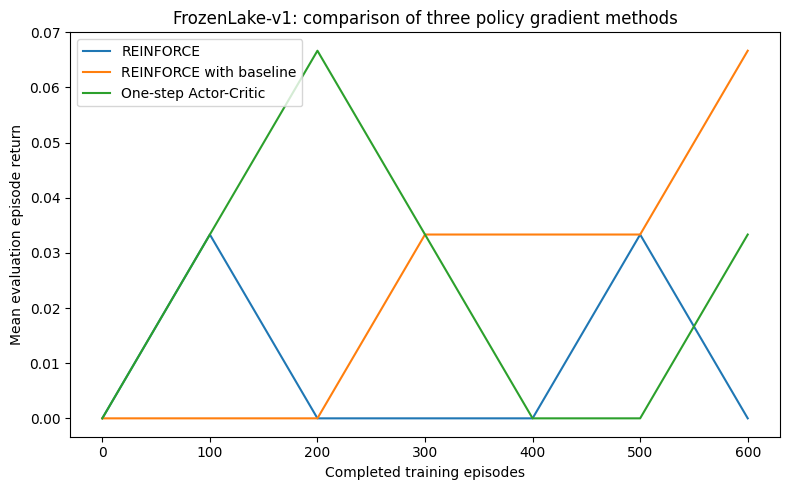

In [32]:
plt.figure(figsize=(8, 5))
for algorithm in FROZENLAKE_ALGORITHM_NAMES:
    runs = [result for result in frozenlake_results if result["algorithm"] == algorithm]
    mean_returns = np.mean([run["evaluation_means"] for run in runs], axis=0)
    plt.plot(runs[0]["evaluation_episodes"], mean_returns, label=algorithm)
    final_mean = np.mean([run["final_mean"] for run in runs])
    print(f"FrozenLake | {algorithm}: final mean return across {len(runs)} runs = {final_mean:.2f}")

plt.xlabel("Completed training episodes")
plt.ylabel("Mean evaluation episode return")
plt.title("FrozenLake-v1: comparison of three policy gradient methods")
plt.legend()
plt.tight_layout()
plt.show()


# CliffWalking: Policy Gradient Methods

The grid has 4 rows and 12 columns. Position IDs range from 0 to 47;
the start is 36 and the goal is 47. Actions are 0: up, 1: right, 2: down,
and 3: left. Movement is deterministic with `is_slippery=False`.

An ordinary step gives -1. Falling into the cliff gives -100 and moves the
player back to the start within the same episode. Reaching the goal ends the
episode. Higher mean episode return is better.

This experiment adds a 200-step finite task horizon, because the base
environment has no time limit. Training and evaluation both stop at the goal
or at this limit. The value network receives remaining time; Actor-Critic
uses only the final reward at either boundary. A fall into the cliff still
uses the next state's value because the episode continues.

Environment rules: [Gymnasium CliffWalking documentation](https://gymnasium.farama.org/environments/toy_text/cliff_walking/).


In [33]:
CLIFFWALKING_TRAIN_EPISODES = TRAIN_EPISODES
CLIFFWALKING_TRAIN_SEEDS = TRAIN_SEEDS
CLIFFWALKING_EVAL_EVERY = EVAL_EVERY
CLIFFWALKING_EVAL_EPISODES = EVAL_EPISODES
CLIFFWALKING_FINAL_EVAL_EPISODES = FINAL_EVAL_EPISODES
CLIFFWALKING_GAMMA = GAMMA
CLIFFWALKING_HIDDEN_SIZE = HIDDEN_SIZE
CLIFFWALKING_DEVICE = EXPERIMENT_DEVICE
CLIFFWALKING_ALGORITHM_NAMES = ALGORITHM_NAMES
CLIFFWALKING_LEARNING_RATES = LEARNING_RATES

CLIFFWALKING_STATE_COUNT = 48
CLIFFWALKING_ACTION_COUNT = 4
CLIFFWALKING_MAX_EPISODE_STEPS = 200


## Networks and observations

The policy input is a one-hot vector of length 48: the observed
state's entry is 1 and every other entry is 0. The state ID is a category,
so its numerical magnitude is not used as an input feature.

The value input appends the fraction of steps remaining to the same state
vector, giving 49 features. At step t, that fraction is
`(MAX_EPISODE_STEPS - t) / MAX_EPISODE_STEPS`, using this environment's limit.

The policy architecture is `Linear(48, 32) -> Tanh -> Linear(32, 4)`.
The value architecture is `Linear(49, 32) -> Tanh -> Linear(32, 1)`.


In [34]:
def make_cliffwalking_environment():
    return gym.make(
        "CliffWalking-v1", max_episode_steps=CLIFFWALKING_MAX_EPISODE_STEPS,
        is_slippery=False,
    )


def cliffwalking_features(observation):
    features = torch.zeros(CLIFFWALKING_STATE_COUNT, dtype=torch.float32, device=CLIFFWALKING_DEVICE)
    features[int(observation)] = 1.0
    return features


def cliffwalking_value_features(observation, step_index):
    remaining_time = torch.tensor(
        [(CLIFFWALKING_MAX_EPISODE_STEPS - step_index) / CLIFFWALKING_MAX_EPISODE_STEPS],
        dtype=torch.float32, device=CLIFFWALKING_DEVICE,
    )
    return torch.cat((cliffwalking_features(observation), remaining_time))


def make_cliffwalking_policy_network(seed):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(seed)
        network = nn.Sequential(
            nn.Linear(CLIFFWALKING_STATE_COUNT, CLIFFWALKING_HIDDEN_SIZE), nn.Tanh(),
            nn.Linear(CLIFFWALKING_HIDDEN_SIZE, CLIFFWALKING_ACTION_COUNT),
        )
    return network.to(CLIFFWALKING_DEVICE)


def make_cliffwalking_value_network(seed):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(seed)
        network = nn.Sequential(
            nn.Linear(CLIFFWALKING_STATE_COUNT + 1, CLIFFWALKING_HIDDEN_SIZE), nn.Tanh(),
            nn.Linear(CLIFFWALKING_HIDDEN_SIZE, 1),
        )
    return network.to(CLIFFWALKING_DEVICE)


## REINFORCE and REINFORCE with baseline


In [35]:
def collect_cliffwalking_episode(policy_network, environment, reset_seed):
    observation, _ = environment.reset(seed=reset_seed)
    observations, actions, rewards = [], [], []
    terminated = truncated = False
    while not (terminated or truncated):
        with torch.no_grad():
            distribution = Categorical(logits=policy_network(cliffwalking_features(observation)))
            action = int(distribution.sample().item())
        next_observation, reward, terminated, truncated, _ = environment.step(action)
        observations.append(observation)
        actions.append(action)
        rewards.append(float(reward))
        observation = next_observation
    return observations, actions, rewards


def train_cliffwalking_reinforce_episode(
    policy_network, policy_optimizer, environment, reset_seed,
    value_network=None, value_optimizer=None,
):
    observations, actions, rewards = collect_cliffwalking_episode(
        policy_network, environment, reset_seed
    )
    features = torch.stack([cliffwalking_features(observation) for observation in observations])
    actions = torch.tensor(actions, dtype=torch.long, device=CLIFFWALKING_DEVICE)
    returns = torch.tensor(
        compute_sampled_returns(rewards, CLIFFWALKING_GAMMA),
        dtype=torch.float32, device=CLIFFWALKING_DEVICE,
    )
    discounts = torch.tensor(
        [CLIFFWALKING_GAMMA ** t for t in range(len(rewards))],
        dtype=torch.float32, device=CLIFFWALKING_DEVICE,
    )
    distribution = Categorical(logits=policy_network(features))
    action_log_probabilities = distribution.log_prob(actions)
    policy_weights = returns

    if value_network is not None:
        value_inputs = torch.stack([
            cliffwalking_value_features(observation, t)
            for t, observation in enumerate(observations)
        ])
        values = value_network(value_inputs).squeeze(-1)
        policy_weights = returns - values.detach()
        value_loss = 0.5 * (values - returns).square().mean()

    policy_loss = -(discounts * policy_weights * action_log_probabilities).sum()
    optimizer_step(policy_loss, policy_optimizer)
    if value_network is not None:
        optimizer_step(value_loss, value_optimizer)


## One-step Actor-Critic


In [36]:
def train_cliffwalking_actor_critic_episode(
    policy_network, policy_optimizer, value_network, value_optimizer,
    environment, reset_seed,
):
    observation, _ = environment.reset(seed=reset_seed)
    terminated = truncated = False
    step_index = 0
    while not (terminated or truncated):
        features = cliffwalking_features(observation)
        distribution = Categorical(logits=policy_network(features))
        action_tensor = distribution.sample()
        action_log_probability = distribution.log_prob(action_tensor)
        value = value_network(cliffwalking_value_features(observation, step_index)).squeeze(-1)
        next_observation, reward, terminated, truncated, _ = environment.step(
            int(action_tensor.item())
        )

        with torch.no_grad():
            if terminated or truncated:
                target = torch.tensor(float(reward), device=CLIFFWALKING_DEVICE)
            else:
                next_value = value_network(
                    cliffwalking_value_features(next_observation, step_index + 1)
                ).squeeze(-1)
                target = float(reward) + CLIFFWALKING_GAMMA * next_value
            td_error = target - value.detach()

        policy_loss = -(CLIFFWALKING_GAMMA ** step_index) * td_error * action_log_probability
        value_loss = 0.5 * (value - target).square()
        optimizer_step(policy_loss, policy_optimizer)
        optimizer_step(value_loss, value_optimizer)
        observation = next_observation
        step_index += 1


## Evaluation


In [37]:
def evaluate_cliffwalking(policy_network, environment_seeds, action_seed):
    environment = make_cliffwalking_environment()
    returns = []
    try:
        with torch.random.fork_rng(devices=[]), torch.no_grad():
            torch.manual_seed(action_seed)
            for environment_seed in environment_seeds:
                observation, _ = environment.reset(seed=environment_seed)
                total_reward = 0.0
                terminated = truncated = False
                while not (terminated or truncated):
                    distribution = Categorical(
                        logits=policy_network(cliffwalking_features(observation))
                    )
                    action = int(distribution.sample().item())
                    observation, reward, terminated, truncated, _ = environment.step(action)
                    total_reward += float(reward)
                returns.append(total_reward)
    finally:
        environment.close()
    return float(np.mean(returns))


## Run the experiment


In [38]:
def run_cliffwalking_training(algorithm, seed):
    torch.manual_seed(seed)
    policy_network = make_cliffwalking_policy_network(seed)
    rates = CLIFFWALKING_LEARNING_RATES[algorithm]
    policy_optimizer = torch.optim.Adam(policy_network.parameters(), lr=rates["policy"])
    value_network = value_optimizer = None
    if algorithm != "REINFORCE":
        value_network = make_cliffwalking_value_network(seed + 10000)
        value_optimizer = torch.optim.Adam(value_network.parameters(), lr=rates["value"])

    environment = make_cliffwalking_environment()
    evaluation_seeds = [1000000 + seed * 1000 + i for i in range(CLIFFWALKING_EVAL_EPISODES)]
    evaluation_episodes, evaluation_means = [], []

    def record_evaluation(episode_number):
        mean_return = evaluate_cliffwalking(policy_network, evaluation_seeds, 3000000 + seed)
        evaluation_episodes.append(episode_number)
        evaluation_means.append(mean_return)
        print(
            f"CliffWalking | {algorithm} | seed={seed} | "
            f"episode={episode_number}/{CLIFFWALKING_TRAIN_EPISODES} | "
            f"eval_mean={mean_return:.2f}", flush=True
        )

    try:
        record_evaluation(0)
        for episode_number in range(1, CLIFFWALKING_TRAIN_EPISODES + 1):
            reset_seed = seed * 10000 + episode_number
            if algorithm == "One-step Actor-Critic":
                train_cliffwalking_actor_critic_episode(
                    policy_network, policy_optimizer, value_network, value_optimizer,
                    environment, reset_seed,
                )
            else:
                train_cliffwalking_reinforce_episode(
                    policy_network, policy_optimizer, environment, reset_seed,
                    value_network, value_optimizer,
                )
            if (episode_number % CLIFFWALKING_EVAL_EVERY == 0
                    or episode_number == CLIFFWALKING_TRAIN_EPISODES):
                record_evaluation(episode_number)

        final_seeds = [
            2000000 + seed * 1000 + i for i in range(CLIFFWALKING_FINAL_EVAL_EPISODES)
        ]
        final_mean = evaluate_cliffwalking(policy_network, final_seeds, 4000000 + seed)
    finally:
        environment.close()

    return {
        "algorithm": algorithm, "seed": seed,
        "evaluation_episodes": evaluation_episodes,
        "evaluation_means": evaluation_means, "final_mean": final_mean,
    }


cliffwalking_results = []
for algorithm in CLIFFWALKING_ALGORITHM_NAMES:
    for seed in CLIFFWALKING_TRAIN_SEEDS:
        result = run_cliffwalking_training(algorithm, seed)
        cliffwalking_results.append(result)
        print(f"Completed CliffWalking | {algorithm}, seed={seed}: final_mean={result['final_mean']:.2f}")


CliffWalking | REINFORCE | seed=42 | episode=0/600 | eval_mean=-2237.30
CliffWalking | REINFORCE | seed=42 | episode=100/600 | eval_mean=-1514.70
CliffWalking | REINFORCE | seed=42 | episode=200/600 | eval_mean=-853.50
CliffWalking | REINFORCE | seed=42 | episode=300/600 | eval_mean=-515.80
CliffWalking | REINFORCE | seed=42 | episode=400/600 | eval_mean=-472.50
CliffWalking | REINFORCE | seed=42 | episode=500/600 | eval_mean=-363.60
CliffWalking | REINFORCE | seed=42 | episode=600/600 | eval_mean=-304.20
Completed CliffWalking | REINFORCE, seed=42: final_mean=-328.70
CliffWalking | REINFORCE | seed=43 | episode=0/600 | eval_mean=-2259.20
CliffWalking | REINFORCE | seed=43 | episode=100/600 | eval_mean=-1675.10
CliffWalking | REINFORCE | seed=43 | episode=200/600 | eval_mean=-1397.90
CliffWalking | REINFORCE | seed=43 | episode=300/600 | eval_mean=-1011.80
CliffWalking | REINFORCE | seed=43 | episode=400/600 | eval_mean=-645.50
CliffWalking | REINFORCE | seed=43 | episode=500/600 | eva

## Compare the three algorithms


CliffWalking | REINFORCE: final mean return across 3 runs = -345.20
CliffWalking | REINFORCE with baseline: final mean return across 3 runs = -328.70
CliffWalking | One-step Actor-Critic: final mean return across 3 runs = -200.00


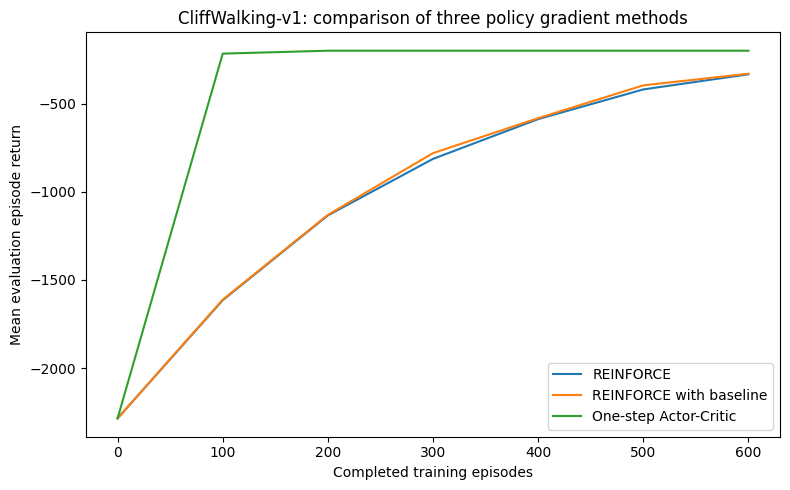

In [39]:
plt.figure(figsize=(8, 5))
for algorithm in CLIFFWALKING_ALGORITHM_NAMES:
    runs = [result for result in cliffwalking_results if result["algorithm"] == algorithm]
    mean_returns = np.mean([run["evaluation_means"] for run in runs], axis=0)
    plt.plot(runs[0]["evaluation_episodes"], mean_returns, label=algorithm)
    final_mean = np.mean([run["final_mean"] for run in runs])
    print(f"CliffWalking | {algorithm}: final mean return across {len(runs)} runs = {final_mean:.2f}")

plt.xlabel("Completed training episodes")
plt.ylabel("Mean evaluation episode return")
plt.title("CliffWalking-v1: comparison of three policy gradient methods")
plt.legend()
plt.tight_layout()
plt.show()


# Week 07: PPO on five environments

Apply PPO-Clip to the same five environments and compare it with the three Week 05 baselines. Use the same CPU setup, networks, 600 training episodes and seeds 42/43/44.

Sources: [Week 07 assignment](https://app.notion.com/p/Week-7-Proximal-Policy-Optimization-40ae55cb6aa78038a728f22235e5cae2) · [PPO paper](https://arxiv.org/pdf/1707.06347).


## PPO settings

Collect 10 episodes, train on their records for four epochs, then collect the next batch. Each epoch shuffles the records into mini-batches of up to 64 transitions; each mini-batch updates both networks once.


In [40]:
PPO_ALGORITHM_NAME = "PPO-Clip"
PPO_SETTINGS = {
    "episodes_per_batch": 10,       # Episodes collected before updating.
    "update_epochs": 4,             # Passes over the batch.
    "minibatch_size": 64,           # Maximum transitions per parameter update.
    "clip_epsilon": 0.2,            # Ratio clipping bounds: 0.8 and 1.2.
    "gae_lambda": 0.95,             # Weight decay for later TD errors.
    "policy_learning_rate": 3e-4,
    "value_learning_rate": 1e-3,
    "entropy_coefficient": 0.01,    # Encourages exploration.
    "normalize_advantages": True,  # Standardize advantages across the batch.
    "max_gradient_norm": 0.5,       # Gradient norm limit for each network.
}


## Collect records and compute GAE

For an episode of $T$ transitions, $s_t$, $a_t$ and $r_t$ are the state, action and reward; $V_{\mathrm{old}}(s_t)$ is the value estimate during collection. Value inputs include remaining time where specified above. The discount factor is $\gamma=1$ and the GAE parameter is $\lambda=0.95$. Set $m_t=0$ at termination or the episode time limit, and $m_t=1$ otherwise.

Let $\delta_t$ be the TD error and $A_t$ the generalized advantage estimate. Compute them backwards for $t=T-1,\ldots,0$:

$$\delta_t=r_t+\gamma m_t V_{\mathrm{old}}(s_{t+1})-V_{\mathrm{old}}(s_t),$$
$$A_t=\delta_t+\gamma\lambda m_t A_{t+1},\qquad A_T=0.$$

The value-training target is $y_t=A_t+V_{\mathrm{old}}(s_t)$. Standardize advantages across the batch for policy training; use the raw advantages to compute $y_t$.


In [41]:
def ppo_episode_advantages(rewards, old_values, gamma, gae_lambda):
    """Compute GAE and value targets for one episode."""
    if not rewards or len(rewards) != len(old_values):
        raise ValueError("Rewards and old values must have the same positive length.")
    advantages = [0.0] * len(rewards)
    next_advantage = 0.0
    for t in reversed(range(len(rewards))):
        continuation = float(t + 1 < len(rewards))
        next_value = float(old_values[t + 1]) if continuation else 0.0
        td_error = float(rewards[t]) + gamma * continuation * next_value - float(old_values[t])
        next_advantage = td_error + gamma * gae_lambda * continuation * next_advantage
        advantages[t] = next_advantage
    targets = [advantage + float(value) for advantage, value in zip(advantages, old_values)]
    return advantages, targets


def collect_ppo_batch(policy_network, value_network, environment, spec,
                      seed, first_episode, episode_count, settings):
    policy_inputs, value_inputs, actions, old_log_probabilities = [], [], [], []
    advantages, value_targets, episode_returns = [], [], []
    with torch.no_grad():
        for episode_number in range(first_episode, first_episode + episode_count):
            observation, _ = environment.reset(seed=seed * 10000 + episode_number)
            rewards, old_values = [], []
            terminated = truncated = False
            step_index = 0
            while not (terminated or truncated):
                policy_input = spec["policy_features"](observation)
                value_input = spec["value_features"](observation, step_index)
                distribution = Categorical(logits=policy_network(policy_input))
                action = distribution.sample()
                old_value = value_network(value_input).squeeze(-1)
                next_observation, reward, terminated, truncated, _ = environment.step(
                    int(action.item())
                )
                policy_inputs.append(policy_input.detach().clone())
                value_inputs.append(value_input.detach().clone())
                actions.append(action.detach().clone())
                old_log_probabilities.append(distribution.log_prob(action).detach().clone())
                rewards.append(float(reward))
                old_values.append(float(old_value.item()))
                observation = next_observation
                step_index += 1
            episode_advantages, episode_targets = ppo_episode_advantages(
                rewards, old_values, spec["gamma"], settings["gae_lambda"]
            )
            advantages.extend(episode_advantages)
            value_targets.extend(episode_targets)
            episode_returns.append(float(sum(rewards)))

    raw_advantages = torch.tensor(advantages, dtype=torch.float32, device=EXPERIMENT_DEVICE)
    policy_advantages = raw_advantages.clone()
    if settings["normalize_advantages"]:
        policy_advantages = (
            (policy_advantages - policy_advantages.mean())
            / policy_advantages.std(unbiased=False).clamp_min(1e-8)
        )
    return {
        "policy_inputs": torch.stack(policy_inputs),
        "value_inputs": torch.stack(value_inputs),
        "actions": torch.stack(actions).long(),
        "old_log_probabilities": torch.stack(old_log_probabilities),
        "advantages": policy_advantages,
        "value_targets": torch.tensor(value_targets, dtype=torch.float32, device=EXPERIMENT_DEVICE),
        "episode_returns": episode_returns,
        "transition_count": len(actions),
    }


## Update the policy and value networks

For each mini-batch $M$, let $\theta$ be the current policy parameters, $\pi_{\mathrm{old}}$ the collection policy, $\widetilde A_t$ the fixed advantage used for policy training (standardized when enabled), and $\epsilon=0.2$. Recompute current probabilities to evaluate the clipped surrogate objective function:

$$\rho_t(\theta)=\frac{\pi_\theta(a_t\mid s_t)}{\pi_{\mathrm{old}}(a_t\mid s_t)},$$
$$J_{\mathrm{clip}}(\theta)=\frac{1}{|M|}\sum_{t\in M}
\min\left(\rho_t(\theta)\widetilde A_t,
\operatorname{clip}(\rho_t(\theta),1-\epsilon,1+\epsilon)\widetilde A_t\right).$$

Adam minimizes the policy and value loss functions using separate networks:

$$L_{\mathrm{policy}}=-J_{\mathrm{clip}}-c_H\overline H,\qquad
L_{\mathrm{value}}=\frac{1}{2|M|}\sum_{t\in M}(V(s_t)-y_t)^2.$$

Here $\overline H$ is the mean entropy of the current action distributions, $c_H=0.01$, and $V$ is the current value network. Old probabilities, advantages and value targets stay fixed during these updates.


In [42]:
def ppo_optimizer_step(loss, optimizer, parameters, max_gradient_norm):
    parameters = list(parameters)
    if not bool(torch.isfinite(loss).item()):
        raise FloatingPointError("Non-finite PPO loss.")
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(parameters, max_gradient_norm, error_if_nonfinite=True)
    optimizer.step()
    if any(not bool(torch.isfinite(parameter).all().item()) for parameter in parameters):
        raise FloatingPointError("Non-finite PPO parameter after update.")


def update_ppo_batch(policy_network, value_network, policy_optimizer, value_optimizer,
                     batch, settings, shuffle_generator):
    count = batch["transition_count"]
    update_count = 0
    for _ in range(settings["update_epochs"]):
        permutation = torch.randperm(count, generator=shuffle_generator)
        for start in range(0, count, settings["minibatch_size"]):
            indices = permutation[start:start + settings["minibatch_size"]]
            distribution = Categorical(logits=policy_network(batch["policy_inputs"][indices]))
            current_log_probabilities = distribution.log_prob(batch["actions"][indices])
            ratios = torch.exp(current_log_probabilities - batch["old_log_probabilities"][indices])
            unclipped_terms = ratios * batch["advantages"][indices]
            clipped_terms = ratios.clamp(
                1.0 - settings["clip_epsilon"], 1.0 + settings["clip_epsilon"]
            ) * batch["advantages"][indices]
            policy_loss = -torch.minimum(unclipped_terms, clipped_terms).mean()
            policy_loss = policy_loss - settings["entropy_coefficient"] * distribution.entropy().mean()

            values = value_network(batch["value_inputs"][indices]).squeeze(-1)
            value_loss = 0.5 * (values - batch["value_targets"][indices]).square().mean()
            ppo_optimizer_step(policy_loss, policy_optimizer, policy_network.parameters(),
                               settings["max_gradient_norm"])
            ppo_optimizer_step(value_loss, value_optimizer, value_network.parameters(),
                               settings["max_gradient_norm"])
            update_count += 1

    with torch.no_grad():
        distribution = Categorical(logits=policy_network(batch["policy_inputs"]))
        log_ratios = distribution.log_prob(batch["actions"]) - batch["old_log_probabilities"]
        ratios = log_ratios.exp()
        diagnostics = {
            "policy_updates": update_count,
            "value_updates": update_count,
            "approximate_kl": float(((ratios - 1.0) - log_ratios).mean().item()),
            "clip_fraction": float(((ratios - 1.0).abs() > settings["clip_epsilon"]).float().mean().item()),
        }
    if not all(np.isfinite(diagnostics[key]) for key in ("approximate_kl", "clip_fraction")):
        raise FloatingPointError("Non-finite PPO diagnostics.")
    return diagnostics


## Environment configuration

Reuse the environment functions and baseline results defined above.


In [43]:
PPO_ENVIRONMENTS = {
    "CartPole-v1": {
        "make_environment": lambda: gym.make("CartPole-v1", max_episode_steps=MAX_EPISODE_STEPS),
        "make_policy": make_policy_network, "make_value": make_value_network,
        "policy_features": observation_to_tensor, "value_features": value_features,
        "evaluate": evaluate_cartpole, "baseline_results": cartpole_results,
    },
    "Blackjack-v1": {
        "make_environment": make_blackjack_environment,
        "make_policy": make_blackjack_policy_network, "make_value": make_blackjack_value_network,
        "policy_features": blackjack_features,
        "value_features": lambda observation, step_index: blackjack_features(observation),
        "evaluate": evaluate_blackjack, "baseline_results": blackjack_results,
    },
    "Taxi-v4": {
        "make_environment": make_taxi_environment,
        "make_policy": make_taxi_policy_network, "make_value": make_taxi_value_network,
        "policy_features": taxi_features, "value_features": taxi_value_features,
        "evaluate": evaluate_taxi, "baseline_results": taxi_results,
    },
    "FrozenLake-v1": {
        "make_environment": make_frozenlake_environment,
        "make_policy": make_frozenlake_policy_network, "make_value": make_frozenlake_value_network,
        "policy_features": frozenlake_features, "value_features": frozenlake_value_features,
        "evaluate": evaluate_frozenlake, "baseline_results": frozenlake_results,
    },
    "CliffWalking-v1": {
        "make_environment": make_cliffwalking_environment,
        "make_policy": make_cliffwalking_policy_network, "make_value": make_cliffwalking_value_network,
        "policy_features": cliffwalking_features, "value_features": cliffwalking_value_features,
        "evaluate": evaluate_cliffwalking, "baseline_results": cliffwalking_results,
    },
}
for spec in PPO_ENVIRONMENTS.values():
    spec.update({
        "gamma": GAMMA, "training_episodes": TRAIN_EPISODES,
        "training_seeds": tuple(TRAIN_SEEDS), "evaluation_interval": EVAL_EVERY,
        "evaluation_episodes": EVAL_EPISODES, "final_evaluation_episodes": FINAL_EVAL_EPISODES,
    })


## Training and evaluation

For each seed, initialize the networks and alternate collection with PPO updates. Evaluate 10 episodes at the start and every 100 training episodes, then run 10 separate final evaluation episodes. Curves average results across three seeds; printed final means use the final evaluations. Logs also report training steps and policy-update counts.


In [44]:
def run_ppo_training(environment_name, seed, settings=None, spec=None, verbose=True):
    settings = dict(PPO_SETTINGS if settings is None else settings)
    spec = dict(PPO_ENVIRONMENTS[environment_name] if spec is None else spec)
    for key in ("episodes_per_batch", "update_epochs", "minibatch_size"):
        if not isinstance(settings[key], int) or settings[key] <= 0:
            raise ValueError(f"{key} must be a positive integer.")
    if spec["training_episodes"] <= 0 or spec["evaluation_interval"] <= 0:
        raise ValueError("Training budget and evaluation interval must be positive.")
    if not 0.0 < settings["clip_epsilon"] < 1.0:
        raise ValueError("clip_epsilon must be between zero and one.")
    if not 0.0 <= settings["gae_lambda"] <= 1.0:
        raise ValueError("gae_lambda must lie in [0, 1].")
    torch.manual_seed(seed)
    shuffle_generator = torch.Generator(device="cpu").manual_seed(seed + 5000000)
    policy_network = spec["make_policy"](seed)
    value_network = spec["make_value"](seed + 10000)
    policy_optimizer = torch.optim.Adam(policy_network.parameters(), lr=settings["policy_learning_rate"])
    value_optimizer = torch.optim.Adam(value_network.parameters(), lr=settings["value_learning_rate"])
    evaluation_seeds = [1000000 + seed * 1000 + i for i in range(spec["evaluation_episodes"])]
    evaluation_episodes, evaluation_means, update_history = [], [], []
    training_steps = policy_updates = value_updates = completed_episodes = 0

    def record_evaluation():
        mean_return = spec["evaluate"](policy_network, evaluation_seeds, 3000000 + seed)
        evaluation_episodes.append(completed_episodes)
        evaluation_means.append(mean_return)
        if verbose:
            print(f"{environment_name} | {PPO_ALGORITHM_NAME} | seed={seed} | "
                  f"episode={completed_episodes}/{spec['training_episodes']} | "
                  f"eval_mean={mean_return:.2f} | steps={training_steps} | "
                  f"policy_updates={policy_updates}", flush=True)

    environment = spec["make_environment"]()
    try:
        record_evaluation()
        while completed_episodes < spec["training_episodes"]:
            until_checkpoint = spec["evaluation_interval"] - completed_episodes % spec["evaluation_interval"]
            episode_count = min(settings["episodes_per_batch"],
                                spec["training_episodes"] - completed_episodes, until_checkpoint)
            batch = collect_ppo_batch(policy_network, value_network, environment, spec, seed,
                                      completed_episodes + 1, episode_count, settings)
            diagnostics = update_ppo_batch(policy_network, value_network, policy_optimizer,
                                            value_optimizer, batch, settings, shuffle_generator)
            completed_episodes += episode_count
            training_steps += batch["transition_count"]
            policy_updates += diagnostics["policy_updates"]
            value_updates += diagnostics["value_updates"]
            update_history.append({"completed_episodes": completed_episodes,
                                   "batch_transitions": batch["transition_count"], **diagnostics})
            if (completed_episodes % spec["evaluation_interval"] == 0
                    or completed_episodes == spec["training_episodes"]):
                record_evaluation()
        final_seeds = [2000000 + seed * 1000 + i for i in range(spec["final_evaluation_episodes"])]
        final_mean = spec["evaluate"](policy_network, final_seeds, 4000000 + seed)
    finally:
        environment.close()
    return {
        "algorithm": PPO_ALGORITHM_NAME, "seed": seed,
        "evaluation_episodes": evaluation_episodes, "evaluation_means": evaluation_means,
        "final_mean": final_mean, "training_steps": training_steps,
        "policy_updates": policy_updates, "value_updates": value_updates,
        "update_history": update_history, "ppo_settings": settings,
    }


def run_ppo_environment(environment_name):
    results = []
    for seed in PPO_ENVIRONMENTS[environment_name]["training_seeds"]:
        result = run_ppo_training(environment_name, seed)
        results.append(result)
        print(f"Completed {environment_name} | {PPO_ALGORITHM_NAME}, seed={seed}: "
              f"final_mean={result['final_mean']:.2f}", flush=True)
    return results


def plot_ppo_comparison(environment_name, ppo_results):
    spec = PPO_ENVIRONMENTS[environment_name]
    results = list(spec["baseline_results"]) + list(ppo_results)
    algorithm_names = tuple(ALGORITHM_NAMES) + (PPO_ALGORITHM_NAME,)
    expected_checkpoints = [0] + list(range(spec["evaluation_interval"],
                                          spec["training_episodes"] + 1,
                                          spec["evaluation_interval"]))
    if expected_checkpoints[-1] != spec["training_episodes"]:
        expected_checkpoints.append(spec["training_episodes"])
    expected_seeds = sorted(spec["training_seeds"])
    for algorithm in algorithm_names:
        runs = [result for result in results if result["algorithm"] == algorithm]
        if sorted(run["seed"] for run in runs) != expected_seeds:
            raise ValueError(f"{algorithm}: rerun all required seeds before comparing.")
        if any(run["evaluation_episodes"] != expected_checkpoints for run in runs):
            raise ValueError(f"{algorithm}: evaluation checkpoints do not match the current budget.")
        if any(len(run["evaluation_means"]) != len(expected_checkpoints) for run in runs):
            raise ValueError(f"{algorithm}: incomplete evaluation results.")
    plt.figure(figsize=(8, 5))
    for algorithm in algorithm_names:
        runs = [result for result in results if result["algorithm"] == algorithm]
        mean_returns = np.mean([run["evaluation_means"] for run in runs], axis=0)
        plt.plot(expected_checkpoints, mean_returns, label=algorithm)
        final_mean = np.mean([run["final_mean"] for run in runs])
        print(f"{environment_name} | {algorithm}: final mean return across "
              f"{len(runs)} runs = {final_mean:.2f}")
    plt.xlabel("Completed training episodes")
    plt.ylabel("Mean evaluation episode return")
    plt.title(f"{environment_name}: PPO and Week 05 baselines")
    plt.legend()
    plt.tight_layout()
    plt.show()


## CartPole-v1


In [45]:
cartpole_ppo_results = run_ppo_environment("CartPole-v1")


CartPole-v1 | PPO-Clip | seed=42 | episode=0/600 | eval_mean=24.00 | steps=0 | policy_updates=0
CartPole-v1 | PPO-Clip | seed=42 | episode=100/600 | eval_mean=29.70 | steps=2472 | policy_updates=180
CartPole-v1 | PPO-Clip | seed=42 | episode=200/600 | eval_mean=45.60 | steps=6420 | policy_updates=440
CartPole-v1 | PPO-Clip | seed=42 | episode=300/600 | eval_mean=162.70 | steps=15226 | policy_updates=1008
CartPole-v1 | PPO-Clip | seed=42 | episode=400/600 | eval_mean=191.50 | steps=36401 | policy_updates=2352
CartPole-v1 | PPO-Clip | seed=42 | episode=500/600 | eval_mean=397.20 | steps=67600 | policy_updates=4320
CartPole-v1 | PPO-Clip | seed=42 | episode=600/600 | eval_mean=470.80 | steps=112011 | policy_updates=7116
Completed CartPole-v1 | PPO-Clip, seed=42: final_mean=471.30
CartPole-v1 | PPO-Clip | seed=43 | episode=0/600 | eval_mean=18.60 | steps=0 | policy_updates=0
CartPole-v1 | PPO-Clip | seed=43 | episode=100/600 | eval_mean=27.80 | steps=2397 | policy_updates=172
CartPole-v1 |

CartPole-v1 | REINFORCE: final mean return across 3 runs = 335.83
CartPole-v1 | REINFORCE with baseline: final mean return across 3 runs = 468.23
CartPole-v1 | One-step Actor-Critic: final mean return across 3 runs = 172.70
CartPole-v1 | PPO-Clip: final mean return across 3 runs = 480.53


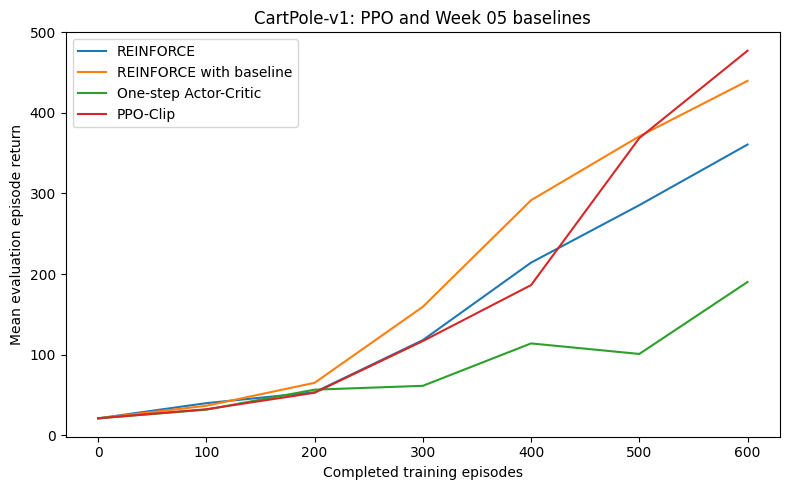

In [46]:
plot_ppo_comparison("CartPole-v1", cartpole_ppo_results)


## Blackjack-v1


In [47]:
blackjack_ppo_results = run_ppo_environment("Blackjack-v1")


Blackjack-v1 | PPO-Clip | seed=42 | episode=0/600 | eval_mean=-0.20 | steps=0 | policy_updates=0
Blackjack-v1 | PPO-Clip | seed=42 | episode=100/600 | eval_mean=-0.30 | steps=124 | policy_updates=40
Blackjack-v1 | PPO-Clip | seed=42 | episode=200/600 | eval_mean=-0.30 | steps=250 | policy_updates=80
Blackjack-v1 | PPO-Clip | seed=42 | episode=300/600 | eval_mean=-0.30 | steps=372 | policy_updates=120
Blackjack-v1 | PPO-Clip | seed=42 | episode=400/600 | eval_mean=-0.10 | steps=486 | policy_updates=160
Blackjack-v1 | PPO-Clip | seed=42 | episode=500/600 | eval_mean=-0.10 | steps=606 | policy_updates=200
Blackjack-v1 | PPO-Clip | seed=42 | episode=600/600 | eval_mean=-0.10 | steps=720 | policy_updates=240
Completed Blackjack-v1 | PPO-Clip, seed=42: final_mean=-0.80
Blackjack-v1 | PPO-Clip | seed=43 | episode=0/600 | eval_mean=-0.80 | steps=0 | policy_updates=0
Blackjack-v1 | PPO-Clip | seed=43 | episode=100/600 | eval_mean=-0.30 | steps=120 | policy_updates=40
Blackjack-v1 | PPO-Clip | s

Blackjack-v1 | REINFORCE: final mean return across 3 runs = -0.53
Blackjack-v1 | REINFORCE with baseline: final mean return across 3 runs = -0.53
Blackjack-v1 | One-step Actor-Critic: final mean return across 3 runs = -0.53
Blackjack-v1 | PPO-Clip: final mean return across 3 runs = -0.67


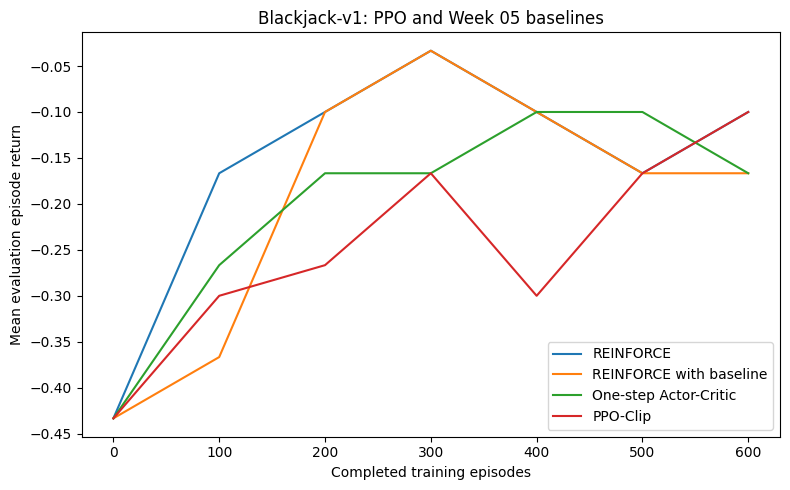

In [48]:
plot_ppo_comparison("Blackjack-v1", blackjack_ppo_results)


## Taxi-v4


In [49]:
taxi_ppo_results = run_ppo_environment("Taxi-v4")


Taxi-v4 | PPO-Clip | seed=42 | episode=0/600 | eval_mean=-793.10 | steps=0 | policy_updates=0
Taxi-v4 | PPO-Clip | seed=42 | episode=100/600 | eval_mean=-297.20 | steps=19723 | policy_updates=1260
Taxi-v4 | PPO-Clip | seed=42 | episode=200/600 | eval_mean=-213.50 | steps=39723 | policy_updates=2540
Taxi-v4 | PPO-Clip | seed=42 | episode=300/600 | eval_mean=-204.50 | steps=59723 | policy_updates=3820
Taxi-v4 | PPO-Clip | seed=42 | episode=400/600 | eval_mean=-200.90 | steps=79723 | policy_updates=5100
Taxi-v4 | PPO-Clip | seed=42 | episode=500/600 | eval_mean=-200.00 | steps=99723 | policy_updates=6380
Taxi-v4 | PPO-Clip | seed=42 | episode=600/600 | eval_mean=-200.00 | steps=119723 | policy_updates=7660
Completed Taxi-v4 | PPO-Clip, seed=42: final_mean=-202.70
Taxi-v4 | PPO-Clip | seed=43 | episode=0/600 | eval_mean=-850.70 | steps=0 | policy_updates=0
Taxi-v4 | PPO-Clip | seed=43 | episode=100/600 | eval_mean=-296.30 | steps=19717 | policy_updates=1260
Taxi-v4 | PPO-Clip | seed=43 | e

Taxi-v4 | REINFORCE: final mean return across 3 runs = -674.57
Taxi-v4 | REINFORCE with baseline: final mean return across 3 runs = -678.40
Taxi-v4 | One-step Actor-Critic: final mean return across 3 runs = -200.90
Taxi-v4 | PPO-Clip: final mean return across 3 runs = -201.20


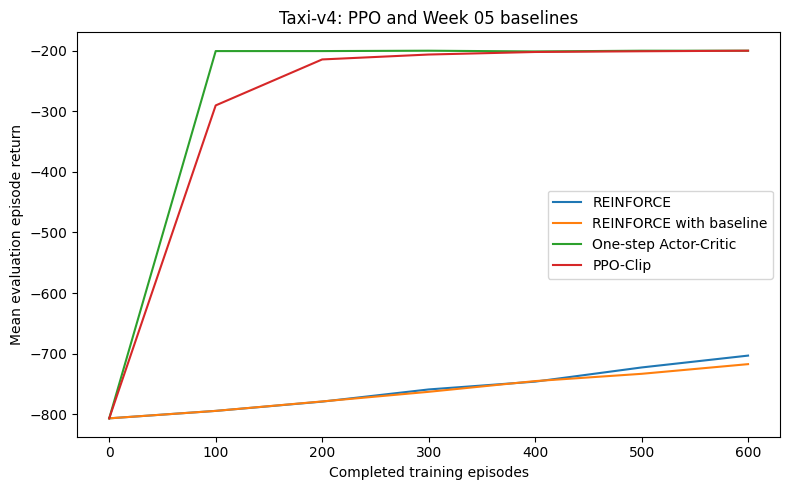

In [50]:
plot_ppo_comparison("Taxi-v4", taxi_ppo_results)


## FrozenLake-v1


In [51]:
frozenlake_ppo_results = run_ppo_environment("FrozenLake-v1")


FrozenLake-v1 | PPO-Clip | seed=42 | episode=0/600 | eval_mean=0.00 | steps=0 | policy_updates=0
FrozenLake-v1 | PPO-Clip | seed=42 | episode=100/600 | eval_mean=0.00 | steps=785 | policy_updates=72
FrozenLake-v1 | PPO-Clip | seed=42 | episode=200/600 | eval_mean=0.00 | steps=1513 | policy_updates=136
FrozenLake-v1 | PPO-Clip | seed=42 | episode=300/600 | eval_mean=0.00 | steps=2236 | policy_updates=208
FrozenLake-v1 | PPO-Clip | seed=42 | episode=400/600 | eval_mean=0.00 | steps=3044 | policy_updates=276
FrozenLake-v1 | PPO-Clip | seed=42 | episode=500/600 | eval_mean=0.00 | steps=3832 | policy_updates=344
FrozenLake-v1 | PPO-Clip | seed=42 | episode=600/600 | eval_mean=0.00 | steps=4576 | policy_updates=420
Completed FrozenLake-v1 | PPO-Clip, seed=42: final_mean=0.00
FrozenLake-v1 | PPO-Clip | seed=43 | episode=0/600 | eval_mean=0.00 | steps=0 | policy_updates=0
FrozenLake-v1 | PPO-Clip | seed=43 | episode=100/600 | eval_mean=0.00 | steps=734 | policy_updates=68
FrozenLake-v1 | PPO-C

FrozenLake-v1 | REINFORCE: final mean return across 3 runs = 0.03
FrozenLake-v1 | REINFORCE with baseline: final mean return across 3 runs = 0.03
FrozenLake-v1 | One-step Actor-Critic: final mean return across 3 runs = 0.07
FrozenLake-v1 | PPO-Clip: final mean return across 3 runs = 0.00


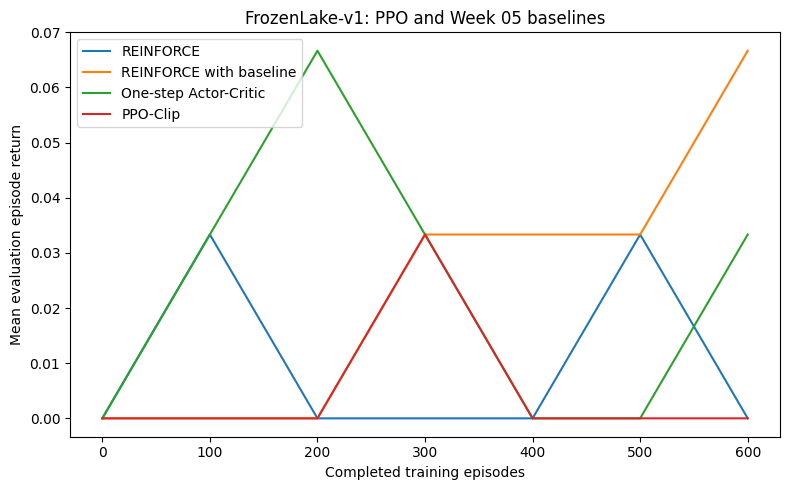

In [52]:
plot_ppo_comparison("FrozenLake-v1", frozenlake_ppo_results)


## CliffWalking-v1


In [53]:
cliffwalking_ppo_results = run_ppo_environment("CliffWalking-v1")


CliffWalking-v1 | PPO-Clip | seed=42 | episode=0/600 | eval_mean=-2237.30 | steps=0 | policy_updates=0
CliffWalking-v1 | PPO-Clip | seed=42 | episode=100/600 | eval_mean=-219.80 | steps=19743 | policy_updates=1264
CliffWalking-v1 | PPO-Clip | seed=42 | episode=200/600 | eval_mean=-249.50 | steps=39743 | policy_updates=2544
CliffWalking-v1 | PPO-Clip | seed=42 | episode=300/600 | eval_mean=-200.00 | steps=59743 | policy_updates=3824
CliffWalking-v1 | PPO-Clip | seed=42 | episode=400/600 | eval_mean=-200.00 | steps=79743 | policy_updates=5104
CliffWalking-v1 | PPO-Clip | seed=42 | episode=500/600 | eval_mean=-200.00 | steps=99743 | policy_updates=6384
CliffWalking-v1 | PPO-Clip | seed=42 | episode=600/600 | eval_mean=-200.00 | steps=119743 | policy_updates=7664
Completed CliffWalking-v1 | PPO-Clip, seed=42: final_mean=-200.00
CliffWalking-v1 | PPO-Clip | seed=43 | episode=0/600 | eval_mean=-2259.20 | steps=0 | policy_updates=0
CliffWalking-v1 | PPO-Clip | seed=43 | episode=100/600 | eval

CliffWalking-v1 | REINFORCE: final mean return across 3 runs = -345.20
CliffWalking-v1 | REINFORCE with baseline: final mean return across 3 runs = -328.70
CliffWalking-v1 | One-step Actor-Critic: final mean return across 3 runs = -200.00
CliffWalking-v1 | PPO-Clip: final mean return across 3 runs = -200.00


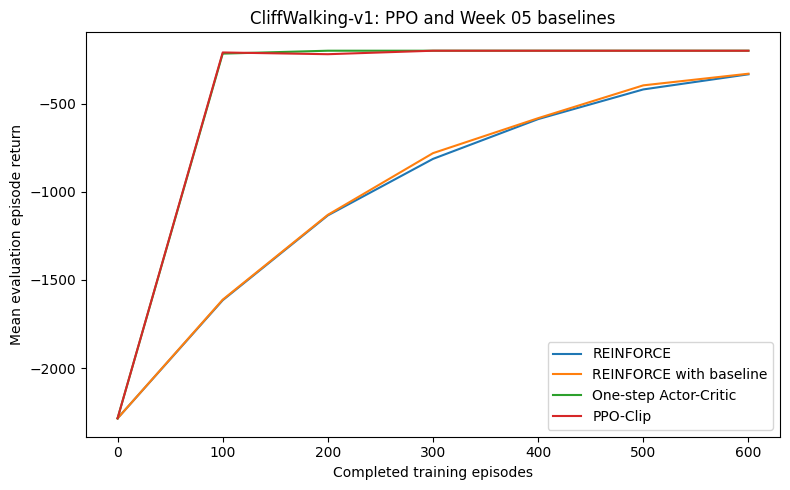

In [54]:
plot_ppo_comparison("CliffWalking-v1", cliffwalking_ppo_results)


## Results

Final mean returns from the saved run (10 separate evaluation episodes per seed, averaged across three seeds):

| Environment | REINFORCE | REINFORCE with baseline | One-step Actor-Critic | PPO-Clip |
|---|---:|---:|---:|---:|
| CartPole | 335.83 | 468.23 | 172.70 | 480.53 |
| Blackjack | -0.53 | -0.53 | -0.53 | -0.67 |
| Taxi | -674.57 | -678.40 | -200.90 | -201.20 |
| FrozenLake | 0.03 | 0.03 | 0.07 | 0.00 |
| CliffWalking | -345.20 | -328.70 | -200.00 | -200.00 |

- **CartPole:** PPO improves strongly in later checkpoints and has the highest final mean, slightly above REINFORCE with baseline.
- **Blackjack:** PPO's checkpoint curve fluctuates, and its separate final mean is below the three baselines.
- **Taxi:** PPO improves towards -200, while Actor-Critic reaches that level earlier. Final returns are similar; returns near the 200-step limit's -200 total do not establish successful delivery.
- **FrozenLake:** All methods have low returns. PPO's 30 final evaluation episodes contain zero successes.
- **CliffWalking:** PPO and Actor-Critic improve rapidly and plateau near -200. This is consistent with reaching the step limit without completing the route.

Under these settings, PPO performs best in CartPole's final evaluation and has mixed results elsewhere. Comparisons use equal episode budgets; interaction-step and parameter-update counts differ between methods.
